**1. Importações e conferência do ambiente**

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
    confusion_matrix, ConfusionMatrixDisplay, cohen_kappa_score, roc_auc_score,
)
from sklearn.tree import export_text, plot_tree

from optuna_arvore_churn import (
    verificar_suporte_categorico, criar_preprocessador, criar_pipeline,
    parametros_baseline, executar_comparacao_podas, melhor_trial_elegivel,
    avaliar_estabilidade_folds, estudar_alpha_fixo,
)

import inspect
import optuna_arvore_churn as modulo_churn
print('Módulo de árvores:', Path(inspect.getfile(modulo_churn)).resolve())
print('Scikit-learn:', verificar_suporte_categorico())
if not hasattr(modulo_churn, 'PREPROCESSAMENTO') or not hasattr(modulo_churn, '_assinatura_dados'):
    raise RuntimeError('Módulo Optuna incompatível: copie o optuna_arvore_churn.py incluído neste pacote.')
PASTA = Path('results/arvore_categorica_110')
PASTA.mkdir(parents=True, exist_ok=True)

Módulo de árvores: C:\Users\joaoh\projeto_ml\costumer-churn-prediction\Entrega_2\decision_tree\optuna_arvore_churn.py
Scikit-learn: 1.10.dev0


c:\Users\joaoh\miniconda3\envs\churn_cat\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


**2. Carregamento e divisão original 70%/30%**

In [ ]:
# DADOS — prioriza a versão temporalmente corrigida se estiver na pasta.
# Se você gerou a versão corrigida com preprocessing_corrigido.py usando o nome
# original, ela também será aceita (mediante auditoria na seção 2.1).
OPCOES_DATASET = [
    Path('./base_churn_5000_VF2_aluno_preprocessada.xlsx')
]
DATASET = next((p for p in OPCOES_DATASET if p.is_file()), None)
if DATASET is None:
    raise FileNotFoundError('Não encontrei a base corrigida. Copie a planilha tratada para a pasta do projeto.')

df = pd.read_excel(DATASET)
colunas_minimas = {'id_cliente', 'churn', 'tempo_cliente_meses'}
if not colunas_minimas.issubset(df.columns):
    raise ValueError(f'Colunas essenciais ausentes: {colunas_minimas - set(df.columns)}')
X = df.drop(columns=['id_cliente', 'churn'])
y = df['churn'].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
print('Dataset:', DATASET.resolve())
print('Total:', len(X), 'Treino:', len(X_train), 'Teste reservado:', len(X_test))
print('Classes no treino:', y_train.value_counts().to_dict())
for coluna in ['tipo_contrato', 'forma_pagamento']:
    print(coluna, X_train[coluna].value_counts(dropna=False).to_dict())
# O KNNImputer é ajustado dentro de cada Pipeline/fold, nunca aqui.

Dataset: C:\Users\joaoh\projeto_ml\costumer-churn-prediction\Entrega_2\decision_tree\base_churn_5000_VF2_aluno_preprocessada.xlsx
Total: 4976 Treino: 3483 Teste reservado: 1493
Classes no treino: {0: 2249, 1: 1234}
tipo_contrato {'Mensal': 1932, 'Anual': 819, 'Bienal': 715, nan: 17}
forma_pagamento {'Boleto': 1364, 'Cartão': 1206, 'Pix': 899, nan: 14}


**2.1. Auditoria de vazamento e proveniência dos dados**

Verifica IDs repetidos e, se a base bruta estiver disponível, confere que tempo_cliente_meses corresponde à data-base de 21/09/2026. Não utiliza rótulos para pré-processar atributos.

In [3]:
# AUDITORIA REEXECUTÁVEL — verifica a base efetivamente carregada.
# NÃO basta checar IDs; verifica a construção temporal a partir da base bruta,
# ou a correspondência exata a uma cópia corrigida previamente conferida.
# Usar a variável como estado permanente era um erro: na seção 13 a auditoria
# será chamada novamente para evitar HISTORICO_COM_VAZAMENTO=None obsoleto.
import hashlib
from optuna_arvore_churn import _assinatura_dados, PREPROCESSAMENTO

DATA_BASE = pd.Timestamp('2026-09-21')
# Assinatura de CONTEÚDO (não do nome do arquivo) da base corrigida que já foi
# reconstruída e confrontada com a base bruta deste projeto.
# Outros datasets só passam se forem verificados contra a respectiva base bruta.
ASSINATURAS_CORRIGIDAS_CONFERIDAS = {
    '695d8405bfca36549aaa99a16ebc64a12d59d44c61b421ae1ea51a64af6aab28'
}

def assinatura_conteudo_dataframe(dados):
    dados = dados.copy()
    dados['id_cliente'] = dados['id_cliente'].astype(str).str.strip().str.upper()
    dados = dados.reindex(sorted(dados.columns), axis=1)
    dados = dados.sort_values('id_cliente').reset_index(drop=True)
    for coluna in dados.select_dtypes(include='number').columns:
        dados[coluna] = pd.to_numeric(dados[coluna], errors='raise').round(8)
    texto = dados.to_csv(index=False, na_rep='<NA>', float_format='%.8f', lineterminator='\n')
    return hashlib.sha256(texto.encode('utf-8')).hexdigest()


def auditar_base_carregada(dados, caminho_dataset, *, verbose=True):
    caminho_dataset = Path(caminho_dataset)
    relatorio = {'dataset': str(caminho_dataset.resolve()), 'linhas': int(len(dados))}
    ids = dados['id_cliente'].astype(str).str.strip().str.upper()
    duplicados = int(ids.duplicated().sum())
    colunas_futuras = sorted(set(dados.columns) & {
        'data_ocorrencia_churn', 'data_final', 'dias_ativo',
        'dias_ativo_na_base', 'data_chamado', 'lista_chamados',
    })
    relatorio.update(duplicados_id=duplicados, colunas_temporalmente_proibidas=colunas_futuras)
    if duplicados or colunas_futuras:
        return False, {**relatorio, 'erro': 'IDs duplicados ou atributos com datas futuras presentes'}
    if 'tempo_cliente_meses' not in dados or 'churn' not in dados:
        return False, {**relatorio, 'erro': 'Colunas necessárias ausentes'}
    if (pd.to_numeric(dados['tempo_cliente_meses'], errors='coerce').isna().any()
            or (pd.to_numeric(dados['tempo_cliente_meses']) < 2).any()):
        return False, {**relatorio, 'erro': 'Tempo de permanência inválido ou cliente com menos de 60 dias'}
    if not set(dados['churn'].dropna().unique()).issubset({0, 1}):
        return False, {**relatorio, 'erro': 'Alvo churn inválido'}

    candidatos_bruta = [
        Path('Entrega_1/base_churn_5000_VF2_aluno.xlsx'),
        Path('base_churn_5000_VF2_aluno.xlsx'),
        caminho_dataset.parent / 'base_churn_5000_VF2_aluno.xlsx',
    ]
    arquivo_bruto = next((p for p in candidatos_bruta if p.is_file()), None)
    relatorio['base_bruta'] = str(arquivo_bruto.resolve()) if arquivo_bruto else None
    if arquivo_bruto is not None:
        # Com base bruta presente, compara não apenas o tempo, mas TODAS as
        # features e o alvo ao preprocessing temporalmente corrigido.
        try:
            from preprocessing_corrigido import preprocessar_base
        except ImportError as exc:
            return False, {**relatorio, 'erro': 'Falta preprocessing_corrigido.py para auditar a base bruta', 'detalhe': str(exc)}
        try:
            esperado = preprocessar_base(pd.read_excel(arquivo_bruto), data_base=DATA_BASE)
            cols = sorted(esperado.columns)
            if set(cols) != set(dados.columns):
                raise ValueError(f'Colunas diferentes da base reconstruída: {set(dados.columns) ^ set(cols)}')
            esperado = esperado.assign(id_cliente=esperado['id_cliente'].astype(str).str.upper().str.strip())
            observado = dados.assign(id_cliente=dados['id_cliente'].astype(str).str.upper().str.strip())
            esperado = esperado.sort_values('id_cliente')[cols].reset_index(drop=True)
            observado = observado.sort_values('id_cliente')[cols].reset_index(drop=True)
            pd.testing.assert_frame_equal(
                observado, esperado, check_dtype=False,
                check_exact=False, rtol=1e-8, atol=1e-8,
            )
        except Exception as exc:
            return False, {**relatorio, 'erro': 'A base tratada NÃO corresponde à reconstrução temporal', 'detalhe': str(exc)[:1200]}
        relatorio['metodo'] = 'Reconstrução e comparação integral contra a base bruta'
        return True, relatorio

    # Sem base bruta, aceita APENAS conteúdo já verificado contra o bruto.
    assinatura = assinatura_conteudo_dataframe(dados)
    relatorio['assinatura_conteudo'] = assinatura
    if assinatura in ASSINATURAS_CORRIGIDAS_CONFERIDAS:
        relatorio['metodo'] = 'Identidade com a base corrigida previamente auditada'
        relatorio['observacao'] = 'Para uma auditoria independente, mantenha a base bruta ao lado do projeto.'
        return True, relatorio

    return False, {**relatorio, 'erro': 'Sem base bruta e sem correspondência com a versão corrigida auditada. Não é possível confirmar ausência de vazamento temporal.'}


def confirmar_auditoria_atual():
    # Comprova também que o arquivo físico não mudou após o carregamento.
    salvo = pd.read_excel(DATASET)
    if assinatura_conteudo_dataframe(salvo) != assinatura_conteudo_dataframe(df):
        raise RuntimeError('O arquivo do dataset mudou após o carregamento: reinicie as células 2 e 2.1.')
    ok, relatorio = auditar_base_carregada(df, DATASET)
    if not ok:
        raise RuntimeError('Auditoria reprovada: ' + json.dumps(relatorio, ensure_ascii=False, default=str))
    if (_assinatura_dados(X_train, y_train) != ASSINATURA_TREINO):
        raise RuntimeError('Os dados de treino mudaram desde a auditoria; recalcule a divisão e confira o Optuna.')
    return relatorio

HISTORICO_COM_VAZAMENTO, relatorio_auditoria = None, {}
_passa, relatorio_auditoria = auditar_base_carregada(df, DATASET)
HISTORICO_COM_VAZAMENTO = not _passa
print('AUDITORIA:', json.dumps(relatorio_auditoria, indent=2, ensure_ascii=False, default=str))
if not _passa:
    raise RuntimeError('A base ainda não foi validada: ' + relatorio_auditoria.get('erro', 'ver relatório'))
ASSINATURA_TREINO = _assinatura_dados(X_train, y_train)
print('Auditoria temporal e de duplicatas: OK')
print('Assinatura do treino:', ASSINATURA_TREINO)
print('Pré-processamento:', PREPROCESSAMENTO)

AUDITORIA: {
  "dataset": "C:\\Users\\joaoh\\projeto_ml\\costumer-churn-prediction\\Entrega_2\\decision_tree\\base_churn_5000_VF2_aluno_preprocessada.xlsx",
  "linhas": 4976,
  "duplicados_id": 0,
  "colunas_temporalmente_proibidas": [],
  "base_bruta": null,
  "assinatura_conteudo": "695d8405bfca36549aaa99a16ebc64a12d59d44c61b421ae1ea51a64af6aab28",
  "metodo": "Identidade com a base corrigida previamente auditada",
  "observacao": "Para uma auditoria independente, mantenha a base bruta ao lado do projeto."
}
Auditoria temporal e de duplicatas: OK
Assinatura do treino: 6ec0c12a8000c1e4
Pré-processamento: categorias_nativas_knn_v1


**3. Confirmação da representação categórica nativa**

In [ ]:
# Este teste usa apenas treinamento e NÃO ajusta nenhum passo em dados do teste.
pre_teste = criar_preprocessador()
X_tr_transformado = pre_teste.fit_transform(X_train)
print('Tipos depois do pré-processamento:')
print(X_tr_transformado.dtypes)
assert str(X_tr_transformado['tipo_contrato'].dtype) == 'category'
assert str(X_tr_transformado['forma_pagamento'].dtype) == 'category'
 
arvore_teste = criar_pipeline({'max_depth': 3})
arvore_teste.fit(X_train, y_train)
print('Máscara categórica da árvore:', arvore_teste.named_steps['arvore'].is_categorical_)
print('Treinamento com textos categóricos: OK')

**4. Subdivisão exclusiva para benchmarks individuais (56%/14% do total)**

In [4]:
X_train_exp, X_val, y_train_exp, y_val = train_test_split(
    X_train, y_train,
    test_size=0.20, random_state=42, stratify=y_train
)
# A imputação é feita pelo pipeline, após o split.
print('Treino experimental:', len(X_train_exp), 'Validação:', len(X_val))

Treino experimental: 2786 Validação: 697


**5. Benchmarks individuais dos hiperparâmetros (um de cada vez)**

Mantemos todos os parâmetros no baseline, alterando somente um por vez. Esta etapa é exploratória, não seleciona a configuração final. Na comparação de podas, usaremos um limiar comum entre as estratégias. Ajuste LIMIAR apenas com informação de treinamento/validação, antes de olhar o teste.

In [5]:
LIMIAR = 0.50  # único limiar para comparar os mecanismos de poda

def metricas_para_limiar(modelo, X_dados, y_dados, limiar):
    idx = list(modelo.named_steps['arvore'].classes_).index(1)
    prob = modelo.predict_proba(X_dados)[:, idx]
    pred = (prob >= limiar).astype(int)
    return {
        'recall': recall_score(y_dados, pred, zero_division=0),
        'precisao': precision_score(y_dados, pred, zero_division=0),
        'f1': f1_score(y_dados, pred, zero_division=0),
        'f2': fbeta_score(y_dados, pred, beta=2, zero_division=0),
        'acuracia': accuracy_score(y_dados, pred),
    }

benchmark_hiperparametros = []
grades = {
    # Hiperparâmetros inteiros
    'max_depth': [None, *range(2, 26)],
    'min_samples_split': range(2, 151, 5),
    'min_samples_leaf': range(1, 81, 3),
    'max_leaf_nodes': [None, *range(2, 151, 5)],
    # Hiperparâmetros contínuos
    'min_impurity_decrease': [
        0, 1e-6, 1e-5, 1e-4, 5e-4, 1e-3, 5e-3
    ],
    'ccp_alpha': [
        0, 1e-6, 1e-5, 1e-4, 5e-4, 1e-3, 5e-3, 2e-2
    ],
    # Hiperparâmetro categórico
    'criterion': ['gini', 'entropy'],
}

for parametro, valores in grades.items():
    for valor in valores:
        parametros = parametros_baseline()
        parametros[parametro] = valor
        modelo = criar_pipeline(parametros)
        modelo.fit(X_train_exp, y_train_exp)
        treino = metricas_para_limiar(modelo, X_train_exp, y_train_exp, LIMIAR)
        validacao = metricas_para_limiar(modelo, X_val, y_val, LIMIAR)
        arvore = modelo.named_steps['arvore']
        benchmark_hiperparametros.append({
            'hiperparametro': parametro, 'valor': str(valor),
            'recall_treino': treino['recall'], 'recall_validacao': validacao['recall'],
            'precisao_validacao': validacao['precisao'],
            'f2_validacao': validacao['f2'],
            'acuracia_treino': treino['acuracia'], 'acuracia_validacao': validacao['acuracia'],
            'gap_acuracia': treino['acuracia'] - validacao['acuracia'],
            'profundidade': arvore.get_depth(), 'folhas': arvore.get_n_leaves(),
        })

df_benchmark = pd.DataFrame(benchmark_hiperparametros)
df_benchmark.to_csv(PASTA / 'benchmark_hiperparametros.csv', index=False)
display(df_benchmark.head(10))

KeyboardInterrupt: 

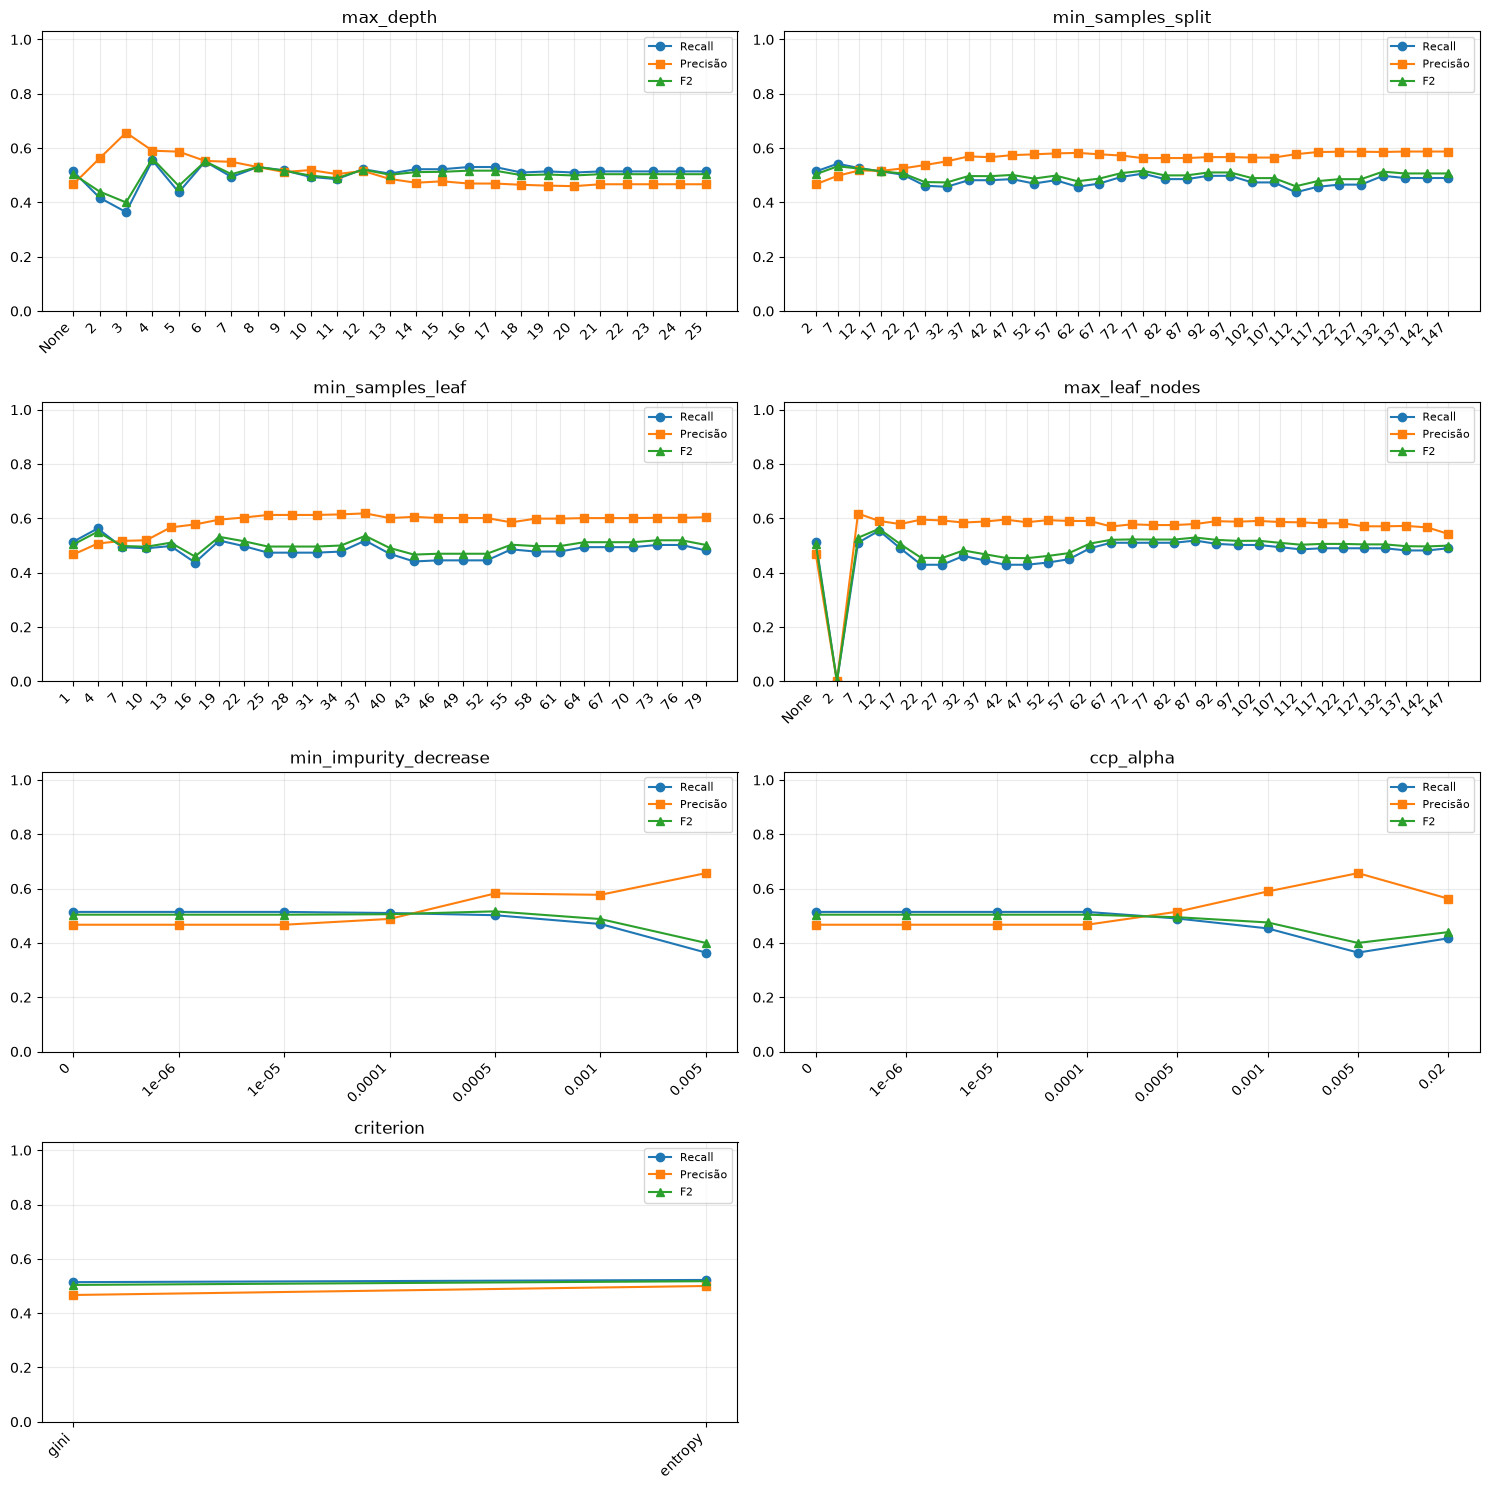

In [69]:
fig, axes = plt.subplots(4, 2, figsize=(15, 15))
for ax, (par, parte) in zip(axes.ravel(), df_benchmark.groupby('hiperparametro', sort=False)):
    eixo_x = np.arange(len(parte))
    ax.plot(eixo_x, parte['recall_validacao'], marker='o', label='Recall')
    ax.plot(eixo_x, parte['precisao_validacao'], marker='s', label='Precisão')
    ax.plot(eixo_x, parte['f2_validacao'], marker='^', label='F2')
    ax.set_xticks(eixo_x)
    ax.set_xticklabels(parte['valor'], rotation=45, ha='right')
    ax.set_ylim(0, 1.03)
    ax.set_title(par)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
for ax in list(axes.ravel())[len(grades):]:
    ax.axis('off')
plt.tight_layout()
plt.savefig(PASTA / 'benchmark_hiperparametros.png', dpi=200)
plt.show()

**6. Comparação Optuna — pré-poda, pós-poda isolada e híbrida**

As três buscas usam o mesmo criterion='gini', o mesmo splitter='best', o mesmo limiar e as mesmas cinco partições.
- Pré-poda: otimiza parâmetros que limitam o crescimento; ccp_alpha=0.
- Pós-poda isolada: usa os valores padrão de crescimento e otimiza somente ccp_alpha.
- Híbrida: permite simultaneamente limitar o crescimento e otimizar ccp_alpha.
- Baseline: árvore sem poda explícita.
Os estudos são novos e persistidos em results/arvore_categorica_110, separados dos resultados anteriores. Se alterar limiar/objetivo/dados, altere também NOME_ESTUDO.

In [6]:
# Configuração do experimento INTERNO. Não execute Optuna para simplesmente ver gráficos.
LIMIAR = 0.24
PRECISAO_MINIMA = 0.45
OBJETIVO = 'f2_churn'       # ou 'recall_churn'
N_TRIALS = 100
N_SPLITS = 5
NOME_ESTUDO = 'E3_t024_f2_prec045_v1'
EXECUTAR_OPTUNA = True     # Mude para True SOMENTE para criar/continuar um estudo

if EXECUTAR_OPTUNA:
    estudos, df_resumo = executar_comparacao_podas(
        X_train, y_train,
        nome_experimento=NOME_ESTUDO,
        limiar=LIMIAR, objetivo=OBJETIVO,
        precisao_minima=PRECISAO_MINIMA, n_trials=N_TRIALS,
        n_splits=N_SPLITS, pasta_results=PASTA, continuar=False,
    )
    print('O Optuna foi executado/reaproveitado. Confira o resumo na seção 6.1.')
else:
    print('Optuna NÃO executado. A seção 6.1 recupera estudos já salvos.')

[I 2026-11-19 08:14:46,413] Using an existing study with `study_name='E3_t024_f2_prec045_v1_pre_poda'` instead of creating a new one.
[I 2026-11-19 08:14:46,782] Using an existing study with `study_name='E3_t024_f2_prec045_v1_pos_poda'` instead of creating a new one.


E3_t024_f2_prec045_v1_pre_poda: reutilizando 100 trials existentes
E3_t024_f2_prec045_v1_pre_poda: recall=0.8598, precisao=0.4625, F2=0.7332


[I 2026-11-19 08:14:47,052] Using an existing study with `study_name='E3_t024_f2_prec045_v1_hibrida'` instead of creating a new one.


E3_t024_f2_prec045_v1_pos_poda: reutilizando 100 trials existentes
E3_t024_f2_prec045_v1_pos_poda: recall=0.8266, precisao=0.4781, F2=0.7206
E3_t024_f2_prec045_v1_hibrida: reutilizando 100 trials existentes
E3_t024_f2_prec045_v1_hibrida: recall=0.8598, precisao=0.4625, F2=0.7332
O Optuna foi executado/reaproveitado. Confira o resumo na seção 6.1.


6.1. Recuperar os estudos após reiniciar o kernel (sem refazer o Optuna)

In [7]:
# Recuperar SEM executar novos trials. Resumo e estudos precisam pertencer
# à base ATUAL, ao mesmo pré-processamento e ao mesmo protocolo.
import optuna
from optuna_arvore_churn import _assinatura_dados, PREPROCESSAMENTO

arquivo_resumo_atual = PASTA / f'resumo_{NOME_ESTUDO}.csv'
if not arquivo_resumo_atual.is_file():
    raise FileNotFoundError(
        f'Falta {arquivo_resumo_atual}. Se é um estudo NOVO, execute a seção 6 '
        'com EXECUTAR_OPTUNA=True. Estudos de outra base NÃO são reutilizáveis.'
    )

arquivo_db = PASTA / 'estudos_optuna_categorico.db'
if not arquivo_db.is_file():
    raise FileNotFoundError(f'Banco de estudos não encontrado: {arquivo_db}')
storage = f'sqlite:///{arquivo_db.resolve().as_posix()}'
estudos = {
    estrategia: optuna.load_study(
        study_name=f'{NOME_ESTUDO}_{estrategia}', storage=storage
    )
    for estrategia in ('pre_poda', 'pos_poda', 'hibrida')
}

assinatura_atual = _assinatura_dados(X_train, y_train)
primeiro = next(iter(estudos.values())).user_attrs
chaves = ('limiar', 'objetivo', 'precisao_minima', 'n_splits',
          'dataset_fingerprint', 'preprocessing')
for nome, estudo in estudos.items():
    for chave in chaves:
        if estudo.user_attrs.get(chave) != primeiro.get(chave):
            raise ValueError(f'Estudos inconsistentes: {nome}, campo {chave}')
    if (estudo.user_attrs.get('dataset_fingerprint') != assinatura_atual or
        estudo.user_attrs.get('preprocessing') != PREPROCESSAMENTO):
        raise ValueError(
            f'O estudo {nome} não corresponde à base/pipeline atuais. '
            'NÃO reutilize os trials antigos; crie novos estudos com outra identificação.'
        )

LIMIAR_ESTUDO = float(primeiro['limiar'])
LIMIAR = LIMIAR_ESTUDO
OBJETIVO = primeiro['objetivo']
PRECISAO_MINIMA = primeiro.get('precisao_minima')
N_SPLITS = int(primeiro['n_splits'])
df_resumo = pd.read_csv(arquivo_resumo_atual)
print(f'Estudo interno carregado: {NOME_ESTUDO}')
print(f'Limiar {LIMIAR:.2f}; objetivo {OBJETIVO}; precisão mínima {PRECISAO_MINIMA}')
print({nome: len(estudo.trials) for nome, estudo in estudos.items()})

Estudo interno carregado: E3_t024_f2_prec045_v1
Limiar 0.24; objetivo f2_churn; precisão mínima 0.45
{'pre_poda': 100, 'pos_poda': 100, 'hibrida': 100}


**6.2. Comparação GERAL do experimento atual — baseline × pré-poda × pós-poda × híbrida (CV1)**

Esta é a comparação original do Optuna, usando somente a primeira validação cruzada (CV1). São quatro estratégias: baseline, melhor pré-poda, melhor pós-poda isolada e melhor híbrida segundo o objetivo indicado na seção 6, respeitando a precisão mínima. Não utiliza CV2 nem os 30% de teste.

Não confundir: a seção 8 analisa até sete candidatos (melhor recall e melhor F2 por estratégia) e usa outra partição dos mesmos 70% de treino. A seção 11 compara apenas os quatro candidatos congelados na CV2, incluindo estabilidade e diferença em relação ao baseline.

In [8]:
# Resumo sucinto da PRIMEIRA validação (CV1) do estudo atual.
# NÃO é a comparação GERAL entre experimentos: esta está na seção 11.
ordem = ['baseline', 'pre_poda', 'pos_poda', 'hibrida']
quadro_cv1 = df_resumo.set_index('estrategia').reindex(ordem).reset_index()
quadro_cv1.insert(1, 'limiar', LIMIAR_ESTUDO)
colunas = ['estrategia', 'limiar', 'elegivel', 'melhor_trial',
           'recall_churn', 'f2_churn', 'precisao_churn', 'acuracia',
           'profundidade', 'folhas']
quadro_cv1.to_csv(PASTA / f'resumo_interno_cv1_{NOME_ESTUDO}.csv', index=False)
print('CV1 — referência da busca, não uma avaliação independente:')
display(quadro_cv1[[c for c in colunas if c in quadro_cv1]].round(4))

CV1 — referência da busca, não uma avaliação independente:


,estrategia,limiar,elegivel,melhor_trial,recall_churn,f2_churn,precisao_churn,acuracia,profundidade,folhas
0,baseline,0.24,True,NaN,0.5284,0.5236,0.5059,0.6491,21.8,741.0
1,pre_poda,0.24,True,87.0,0.8598,0.7332,0.4625,0.5955,4.0,15.8
2,pos_poda,0.24,True,21.0,0.8266,0.7206,0.4781,0.6173,6.6,17.0
3,hibrida,0.24,True,74.0,0.8598,0.7332,0.4625,0.5955,4.0,15.8


**7. Selecionar os melhores por recall e por F2 — primeira validação**

In [11]:
# Selecione o melhor recall e o melhor F2 de cada estratégia APENAS pela CV1.
# Se forem a MESMA configuração, registre um único candidato e um alias;
# isso evita tabelas/gráficos duplicados e mantém as opções disponíveis.
from optuna.trial import TrialState

PASTA_INTERNA = PASTA / 'analises_internas' / NOME_ESTUDO
PASTA_INTERNA.mkdir(parents=True, exist_ok=True)

LIMIAR_ESTUDO = float(next(iter(estudos.values())).user_attrs['limiar'])
NOMES_ESTRATEGIAS = {
    'baseline': 'Baseline (sem poda)',
    'pre_poda': 'Pré-poda isolada',
    'pos_poda': 'Pós-poda isolada',
    'hibrida': 'Poda híbrida (pré + pós)',
}

candidatos_duas_metricas = {
    'baseline': {
        'estrategia': 'baseline',
        'criterios': ['Referência'], 'trial': None,
        'parametros': parametros_baseline(), 'limiar': LIMIAR_ESTUDO,
    }
}
ALIAS_CANDIDATOS = {}

for estrategia, estudo in estudos.items():
    trials = [
        t for t in estudo.trials
        if t.state == TrialState.COMPLETE and t.value is not None
        and t.user_attrs.get('elegivel')
        and 'parametros_arvore' in t.user_attrs
    ]
    if not trials:
        print(f'AVISO: {estrategia} não tem trials elegíveis; será omitido.')
        continue
    for metrica, sufixo, descricao in [
        ('recall_churn', 'recall', 'Melhor recall'),
        ('f2_churn', 'f2', 'Melhor F2'),
    ]:
        trial = max(trials, key=lambda t: (
            float(t.user_attrs[metrica]),
            float(t.user_attrs['precisao_churn']),
            -float(t.user_attrs.get('folhas', 1e12)),
        ))
        nome = f'{estrategia}_{sufixo}'
        params = dict(trial.user_attrs['parametros_arvore'])
        duplicado = next((
            chave for chave, item in candidatos_duas_metricas.items()
            if item['estrategia'] == estrategia and item['parametros'] == params
            and item['limiar'] == LIMIAR_ESTUDO
        ), None)
        if duplicado is not None:
            ALIAS_CANDIDATOS[nome] = duplicado
            candidatos_duas_metricas[duplicado]['criterios'].append(descricao)
            continue
        candidatos_duas_metricas[nome] = {
            'estrategia': estrategia, 'criterios': [descricao],
            'trial': int(trial.number), 'parametros': params,
            'limiar': LIMIAR_ESTUDO,
            'recall_cv1': float(trial.user_attrs['recall_churn']),
            'f2_cv1': float(trial.user_attrs['f2_churn']),
            'precisao_cv1': float(trial.user_attrs['precisao_churn']),
            'acuracia_cv1': float(trial.user_attrs['acuracia']),
        }

base = df_resumo.loc[df_resumo['estrategia'] == 'baseline'].iloc[0]
candidatos_duas_metricas['baseline'].update({
    'recall_cv1': float(base['recall_churn']),
    'f2_cv1': float(base['f2_churn']),
    'precisao_cv1': float(base['precisao_churn']),
    'acuracia_cv1': float(base['acuracia']),
})

def rotulo_modelo(nome, curto=False):
    nome = ALIAS_CANDIDATOS.get(nome, nome)
    config = candidatos_duas_metricas[nome]
    tipo = NOMES_ESTRATEGIAS[config['estrategia']]
    criterio = ' e '.join(config['criterios'])
    label = f'{tipo} · {criterio} · limiar={config["limiar"]:.2f}'
    if not curto and config['trial'] is not None:
        label += f' · trial #{config["trial"]}'
    return label

linhas_cv1 = []
for nome, config in candidatos_duas_metricas.items():
    linhas_cv1.append({
        'modelo': nome, 'rotulo': rotulo_modelo(nome),
        'estrategia': config['estrategia'],
        'criterio_selecao': ' + '.join(config['criterios']),
        'trial': config['trial'], 'limiar': config['limiar'],
        **{m: config[m] for m in (
            'recall_cv1', 'f2_cv1', 'precisao_cv1', 'acuracia_cv1'
        )},
    })
df_primeira_cv = pd.DataFrame(linhas_cv1)
df_primeira_cv.to_csv(PASTA_INTERNA / 'candidatos_recall_f2_cv1.csv', index=False)
print(f'CV1: {len(df_primeira_cv)} configurações únicas dentro das estratégias.')
if ALIAS_CANDIDATOS:
    print('Critérios que escolheram a mesma configuração:', ALIAS_CANDIDATOS)
display(df_primeira_cv.round(4))

CV1: 4 configurações únicas dentro das estratégias.
Critérios que escolheram a mesma configuração: {'pre_poda_f2': 'pre_poda_recall', 'pos_poda_f2': 'pos_poda_recall', 'hibrida_f2': 'hibrida_recall'}


,modelo,rotulo,estrategia,criterio_selecao,trial,limiar,recall_cv1,f2_cv1,precisao_cv1,acuracia_cv1
0,baseline,Baseline (sem poda) · Referência · limiar=0.24,baseline,Referência,NaN,0.24,0.5284,0.5236,0.5059,0.6491
1,pre_poda_recall,Pré-poda isolada · Melhor recall e Melhor F2 ·...,pre_poda,Melhor recall + Melhor F2,87.0,0.24,0.8598,0.7332,0.4625,0.5955
2,pos_poda_recall,Pós-poda isolada · Melhor recall e Melhor F2 ·...,pos_poda,Melhor recall + Melhor F2,36.0,0.24,0.8266,0.7206,0.4781,0.6173
3,hibrida_recall,Poda híbrida (pré + pós) · Melhor recall e Mel...,hibrida,Melhor recall + Melhor F2,74.0,0.24,0.8598,0.7332,0.4625,0.5955


**8. Segunda validação cruzada interna (CV2) — cálculo e cache**

Reavalia candidatos da CV1 usando somente os 70% de treinamento, com outros folds e KNN ajustado dentro do treino de cada fold. Cria comparacao_primeira_segunda_validacao.csv, segunda_validacao_por_fold.csv e predições OOF. O cache só é reutilizado quando a assinatura dos dados e dos candidatos coincide.

In [12]:
# Segunda validação cruzada (CV2): gera o CSV que faltava no notebook anterior.
# A CV2 usa os mesmos 70% de treinamento, com novos folds, e NÃO consulta X_test.
from sklearn.tree import DecisionTreeClassifier
from optuna_arvore_churn import _assinatura_dados, PREPROCESSAMENTO
import hashlib

SEMENTE_CV2 = 2026
RECALCULAR_CV2 = False  # True somente se quiser refazer esta CV
PASTA_INTERNA = PASTA / 'analises_internas' / NOME_ESTUDO
PASTA_INTERNA.mkdir(parents=True, exist_ok=True)

arquivos_cv2 = {
    'folds': PASTA_INTERNA / 'segunda_validacao_por_fold.csv',
    'oof': PASTA_INTERNA / 'predicoes_oof_segunda_validacao.csv',
    'manifesto': PASTA_INTERNA / 'manifesto_cv2.json',
}
assinaturas_modelos = {
    nome: {'parametros': c['parametros'], 'limiar': float(c['limiar'])}
    for nome, c in candidatos_duas_metricas.items()
}
assinatura_cv2 = hashlib.sha256(json.dumps({
    'dataset': _assinatura_dados(X_train, y_train),
    'preprocessamento': PREPROCESSAMENTO,
    'n_splits': N_SPLITS, 'semente': SEMENTE_CV2,
    'candidatos': assinaturas_modelos,
}, sort_keys=True, default=str).encode()).hexdigest()

reusar_cv2 = False
if not RECALCULAR_CV2 and all(p.exists() for p in arquivos_cv2.values()):
    manifesto = json.loads(arquivos_cv2['manifesto'].read_text(encoding='utf-8'))
    reusar_cv2 = manifesto.get('assinatura') == assinatura_cv2

if reusar_cv2:
    print('CV2: resultados compatíveis recuperados, sem novos treinos.')
    df_cv2_folds = pd.read_csv(arquivos_cv2['folds'])
    df_cv2_oof = pd.read_csv(arquivos_cv2['oof'])
else:
    print('CV2: executando nos dados de treino e salvando os resultados...')
    cv2 = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEMENTE_CV2)
    linhas_cv2, linhas_oof_cv2 = [], []

    for fold, (ind_tr, ind_val) in enumerate(cv2.split(X_train, y_train), 1):
        X_tr, X_valid = X_train.iloc[ind_tr], X_train.iloc[ind_val]
        y_tr, y_valid = y_train.iloc[ind_tr], y_train.iloc[ind_val]
        # Imputação aprende APENAS no treino do fold.
        pre = criar_preprocessador()
        X_tr_proc = pre.fit_transform(X_tr)
        X_valid_proc = pre.transform(X_valid)
        previsoes_cache = {}

        for nome, config in candidatos_duas_metricas.items():
            params = dict(config['parametros'])
            params.pop('random_state', None)
            params.pop('categorical_features', None)
            chave = json.dumps(
                {'parametros': params, 'limiar': float(config['limiar'])},
                sort_keys=True, default=str
            )
            if chave not in previsoes_cache:
                arvore = DecisionTreeClassifier(
                    categorical_features='from_dtype', random_state=42, **params
                )
                arvore.fit(X_tr_proc, y_tr)
                indice = list(arvore.classes_).index(1)
                prob = arvore.predict_proba(X_valid_proc)[:, indice]
                pred = (prob >= float(config['limiar'])).astype(int)
                previsoes_cache[chave] = (pred, prob, arvore)
            pred, prob, arvore = previsoes_cache[chave]

            linhas_cv2.append({
                'modelo': nome, 'fold': fold,
                'recall': recall_score(y_valid, pred, zero_division=0),
                'precisao': precision_score(y_valid, pred, zero_division=0),
                'f2': fbeta_score(y_valid, pred, beta=2, zero_division=0),
                'acuracia': accuracy_score(y_valid, pred),
                'nos': arvore.tree_.node_count,
                'folhas': arvore.get_n_leaves(),
                'profundidade': arvore.get_depth(),
            })
            for pos, real, previsto in zip(ind_val, y_valid.to_numpy(), pred):
                linhas_oof_cv2.append({
                    'modelo': nome, 'fold': fold, 'posicao_treino': int(pos),
                    'y_real': int(real), 'y_pred': int(previsto),
                })

    df_cv2_folds = pd.DataFrame(linhas_cv2)
    df_cv2_oof = pd.DataFrame(linhas_oof_cv2)
    df_cv2_folds.to_csv(arquivos_cv2['folds'], index=False)
    df_cv2_oof.to_csv(arquivos_cv2['oof'], index=False)
    arquivos_cv2['manifesto'].write_text(
        json.dumps({'assinatura': assinatura_cv2, 'experimento': NOME_ESTUDO}, indent=2),
        encoding='utf-8'
    )

for nome, parte in df_cv2_oof.groupby('modelo'):
    pos = parte['posicao_treino'].to_numpy(dtype=int)
    if len(parte) != len(X_train) or set(pos) != set(range(len(X_train))):
        raise ValueError(f'OOF da CV2 incompleta para {nome}')
    if not np.array_equal(
        parte['y_real'].to_numpy(dtype=int),
        y_train.iloc[pos].to_numpy(dtype=int)
    ):
        raise ValueError(f'OOF da CV2 corresponde a outros dados: {nome}')

df_cv2_resumo = df_cv2_folds.groupby('modelo', as_index=False).agg(
    recall_cv2=('recall', 'mean'), recall_dp=('recall', 'std'),
    f2_cv2=('f2', 'mean'), f2_dp=('f2', 'std'),
    precisao_cv2=('precisao', 'mean'), precisao_dp=('precisao', 'std'),
    acuracia_cv2=('acuracia', 'mean'), acuracia_dp=('acuracia', 'std'),
    nos_medios=('nos', 'mean'), folhas_medias=('folhas', 'mean'),
    profundidade_media=('profundidade', 'mean'),
)
df_comparacao_cv1_cv2 = df_primeira_cv.merge(
    df_cv2_resumo, on='modelo', validate='one_to_one'
)
df_comparacao_cv1_cv2.to_csv(
    PASTA_INTERNA / 'comparacao_primeira_segunda_validacao.csv', index=False
)
print('Comparação interna CV1 × CV2:')
display(df_comparacao_cv1_cv2[[
    'modelo', 'limiar', 'criterio_selecao',
    'recall_cv1', 'recall_cv2', 'f2_cv1', 'f2_cv2',
    'precisao_cv1', 'precisao_cv2', 'acuracia_cv1', 'acuracia_cv2',
]].round(4))

CV2: executando nos dados de treino e salvando os resultados...
Comparação interna CV1 × CV2:


,modelo,limiar,criterio_selecao,recall_cv1,recall_cv2,f2_cv1,f2_cv2,precisao_cv1,precisao_cv2,acuracia_cv1,acuracia_cv2
0,baseline,0.24,Referência,0.5284,0.5113,0.5236,0.5066,0.5059,0.4894,0.6491,0.6374
1,pre_poda_recall,0.24,Melhor recall + Melhor F2,0.8598,0.8476,0.7332,0.7253,0.4625,0.4610,0.5955,0.5943
2,pos_poda_recall,0.24,Melhor recall + Melhor F2,0.8266,0.8249,0.7206,0.7163,0.4781,0.4712,0.6173,0.6084
3,hibrida_recall,0.24,Melhor recall + Melhor F2,0.8598,0.8476,0.7332,0.7253,0.4625,0.4610,0.5955,0.5943


**8.1. Matrizes OOF dos destaques por recall e F2**

Diagnóstico dos candidatos com maior recall e F2, sem repetir matrizes equivalentes. A CV2 usa os mesmos 70% (em novas divisões); portanto, não é teste independente. A seção 11 contém a comparação interna completa.

,modelo,TN,FP,FN,TP,recall_oof,precisao_oof,f2_oof,acuracia_oof,frac_prevista_churn
0,baseline,1589,660,603,631,0.5113,0.4888,0.5067,0.6374,0.3707
1,pre_poda_recall,1024,1225,188,1046,0.8476,0.4606,0.7257,0.5943,0.6520
2,pos_poda_recall,1101,1148,216,1018,0.8250,0.4700,0.7167,0.6084,0.6219
3,hibrida_recall,1024,1225,188,1046,0.8476,0.4606,0.7257,0.5943,0.6520


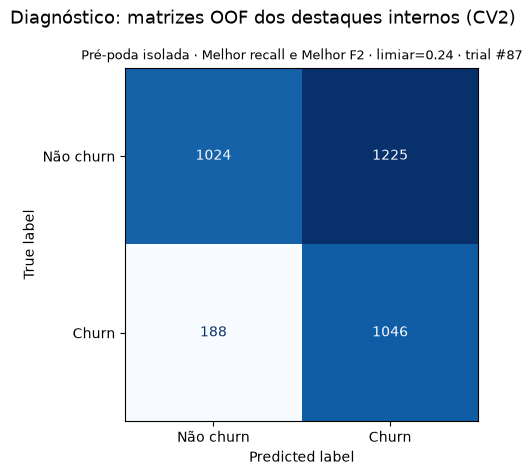

In [13]:
# Uma única galeria de diagnóstico, usando previsões OOF já produzidas pela CV2.
# NÃO repete as matrizes finais nos 30% de teste.
if 'df_cv2_oof' not in globals():
    df_cv2_oof = pd.read_csv(PASTA_INTERNA / 'predicoes_oof_segunda_validacao.csv')
if 'df_cv2_resumo' not in globals():
    df_cv2_resumo = pd.read_csv(PASTA_INTERNA / 'comparacao_primeira_segunda_validacao.csv')

for nome, parte in df_cv2_oof.groupby('modelo'):
    pos = parte['posicao_treino'].to_numpy(dtype=int)
    if (len(parte) != len(X_train) or len(np.unique(pos)) != len(X_train) or
        not np.array_equal(parte['y_real'].to_numpy(dtype=int),
                           y_train.iloc[pos].to_numpy(dtype=int))):
        raise ValueError(f'Predições OOF incorretas para {nome}')

metricas_matriz = []
for nome, p in df_cv2_oof.groupby('modelo', sort=False):
    tn, fp, fn, tp = confusion_matrix(p['y_real'], p['y_pred'], labels=[0,1]).ravel()
    metricas_matriz.append({
        'modelo': nome, 'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp),
        'recall_oof': recall_score(p['y_real'], p['y_pred'], zero_division=0),
        'precisao_oof': precision_score(p['y_real'], p['y_pred'], zero_division=0),
        'f2_oof': fbeta_score(p['y_real'], p['y_pred'], beta=2, zero_division=0),
        'acuracia_oof': accuracy_score(p['y_real'], p['y_pred']),
        'frac_prevista_churn': (p['y_pred'] == 1).mean(),
    })
df_matrizes_oof = pd.DataFrame(metricas_matriz)
df_matrizes_oof.to_csv(PASTA_INTERNA / 'matrizes_oof_metricas.csv', index=False)
display(df_matrizes_oof.round(4))

ranking = df_comparacao_cv1_cv2.copy()
ref = ranking.sort_values(['recall_cv2', 'f2_cv2'], ascending=False).iloc[0]['modelo']
if PRECISAO_MINIMA is None:
    elegiveis = ranking.copy()
else:
    elegiveis = ranking.loc[ranking['precisao_cv2'] >= PRECISAO_MINIMA]

MODELOS_DESTAQUE_CV2 = {'Maior recall (livre)': ref}
if not elegiveis.empty:
    MODELOS_DESTAQUE_CV2['Recall com precisão mínima'] = (
        elegiveis.sort_values(['recall_cv2', 'f2_cv2'], ascending=False).iloc[0]['modelo']
    )
    MODELOS_DESTAQUE_CV2['F2 com precisão mínima'] = (
        elegiveis.sort_values(['f2_cv2', 'recall_cv2'], ascending=False).iloc[0]['modelo']
    )
else:
    print('ATENÇÃO: ninguém satisfez a precisão mínima na CV2.')

# Não mostrar a mesma matriz várias vezes por critérios ou hiperparâmetros iguais.
selecionados, assinaturas = [], set()
for nome in MODELOS_DESTAQUE_CV2.values():
    cfg = candidatos_duas_metricas[nome]
    assinatura = json.dumps(
        {'p': cfg['parametros'], 'l': cfg['limiar']}, sort_keys=True, default=str
    )
    if assinatura not in assinaturas:
        assinaturas.add(assinatura)
        selecionados.append(nome)

fig, axs = plt.subplots(1, len(selecionados), figsize=(5.4*len(selecionados), 4.8))
axs = np.atleast_1d(axs)
for ax, nome in zip(axs, selecionados):
    p = df_cv2_oof.loc[df_cv2_oof['modelo'] == nome]
    ConfusionMatrixDisplay.from_predictions(
        p['y_real'], p['y_pred'], labels=[0,1],
        display_labels=['Não churn', 'Churn'], cmap='Blues',
        colorbar=False, values_format='d', ax=ax,
    )
    ax.set_title(rotulo_modelo(nome), fontsize=9)
fig.suptitle('Diagnóstico: matrizes OOF dos destaques internos (CV2)', fontsize=13)
plt.tight_layout()
plt.savefig(PASTA_INTERNA / 'matrizes_destaques_cv2.png', dpi=220, bbox_inches='tight')
plt.show()

for nome in selecionados:
    linha = df_matrizes_oof.set_index('modelo').loc[nome]
    if linha['frac_prevista_churn'] >= 0.9999:
        print(f'ALERTA: {rotulo_modelo(nome)} prevê TODOS como churn (recall artificialmente 1).')

**9. Estudo detalhado de ccp_alpha: nós, folhas, profundidade e desempenho**

Mantemos todos os hiperparâmetros fixos e variamos apenas ccp_alpha, com o mesmo esquema de validação cruzada. Faremos dois cenários, que respondem a perguntas diferentes:
1. Pós-poda isolada: árvore sem pré-poda explícita; alteramos somente ccp_alpha.
2. Pós-poda sobre pré-poda fixa: mantemos a configuração selecionada de pré-poda e variamos somente ccp_alpha. Mede o benefício adicional da pós-poda.
A profundidade da árvore é sua altura em quantidade de arestas; o número de nós é arvore.tree_.node_count (inclui nós internos e folhas). Também mostramos o total de folhas. As métricas são de validação, não do teste final.

In [14]:
# Seção 9: análise AUTÔNOMA de ccp_alpha, sem depender de versão instalada
# da função estudar_alpha_fixo (que anteriormente omitida 'acuracia').
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, fbeta_score

MODELO_PRE_FIXO = ('pre_poda_f2' if 'pre_poda_f2' in candidatos_duas_metricas
                  else 'pre_poda_recall')
alphas = np.r_[0.0, np.geomspace(1e-6, 3e-2, 36)]
cenarios_alpha = {'Pós-poda isolada': parametros_baseline()}
if MODELO_PRE_FIXO in candidatos_duas_metricas:
    cenarios_alpha['Pós-poda sobre pré-poda fixa'] = dict(
        candidatos_duas_metricas[MODELO_PRE_FIXO]['parametros']
    )
else:
    print('Sem pré-poda elegível: avaliando apenas a pós-poda isolada.')

# Pré-processamento ajustado somente com o treino de cada fold — nenhum leakage.
cv_alpha = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=42)
folds_alpha = []
for fold, (it, iv) in enumerate(cv_alpha.split(X_train, y_train), 1):
    pre = criar_preprocessador()
    Xt = pre.fit_transform(X_train.iloc[it])
    Xv = pre.transform(X_train.iloc[iv])
    folds_alpha.append((fold, Xt, Xv, y_train.iloc[it], y_train.iloc[iv]))

linhas_alpha = []
for cenario, configuracao_fixa in cenarios_alpha.items():
    params_fixos = dict(configuracao_fixa)
    for chave in ('ccp_alpha', 'categorical_features', 'random_state'):
        params_fixos.pop(chave, None)
    for fold, Xt, Xv, yt, yv in folds_alpha:
        for alpha in alphas:
            arvore = DecisionTreeClassifier(
                categorical_features='from_dtype',
                random_state=42, ccp_alpha=float(alpha), **params_fixos,
            )
            arvore.fit(Xt, yt)
            pos_churn = list(arvore.classes_).index(1)
            prob = arvore.predict_proba(Xv)[:, pos_churn]
            pred = (prob >= LIMIAR).astype(int)
            linhas_alpha.append({
                'cenario': cenario, 'fold': fold, 'ccp_alpha': float(alpha),
                'recall': recall_score(yv, pred, zero_division=0),
                'precisao': precision_score(yv, pred, zero_division=0),
                'f2': fbeta_score(yv, pred, beta=2, zero_division=0),
                'acuracia': accuracy_score(yv, pred),
                'nos': int(arvore.tree_.node_count),
                'folhas': int(arvore.get_n_leaves()),
                'profundidade': int(arvore.get_depth()),
            })

df_alpha_folds = pd.DataFrame(linhas_alpha)
colunas_esperadas = ['cenario', 'ccp_alpha', 'nos', 'folhas', 'profundidade',
                      'recall', 'precisao', 'f2', 'acuracia']
assert set(colunas_esperadas).issubset(df_alpha_folds.columns), df_alpha_folds.columns.tolist()
df_alpha_resumo = df_alpha_folds.groupby(
    ['cenario', 'ccp_alpha'], as_index=False
)[['nos', 'folhas', 'profundidade', 'recall', 'precisao', 'f2', 'acuracia']].mean()

PASTA_INTERNA.mkdir(parents=True, exist_ok=True)
df_alpha_folds.to_csv(PASTA_INTERNA / 'alpha_todos_folds.csv', index=False)
df_alpha_resumo.to_csv(PASTA_INTERNA / 'alpha_estrutura_e_metricas.csv', index=False)
display(df_alpha_resumo[colunas_esperadas].round(5).groupby('cenario').head(6))
print('OK — acurácia presente:', 'acuracia' in df_alpha_resumo.columns)

,cenario,ccp_alpha,nos,folhas,profundidade,recall,precisao,f2,acuracia
0,Pós-poda isolada,0.0,1481.0,741.0,21.8,0.52838,0.50592,0.52361,0.64915
1,Pós-poda isolada,0.0,1481.0,741.0,21.8,0.52838,0.50592,0.52361,0.64915
2,Pós-poda isolada,0.0,1481.0,741.0,21.8,0.52838,0.50592,0.52361,0.64915
3,Pós-poda isolada,0.0,1481.0,741.0,21.8,0.52838,0.50592,0.52361,0.64915
4,Pós-poda isolada,0.0,1481.0,741.0,21.8,0.52838,0.50592,0.52361,0.64915
5,Pós-poda isolada,0.0,1481.0,741.0,21.8,0.52838,0.50592,0.52361,0.64915
37,Pós-poda sobre pré-poda fixa,0.0,30.6,15.8,4.0,0.85977,0.46248,0.73325,0.59547
38,Pós-poda sobre pré-poda fixa,0.0,30.6,15.8,4.0,0.85977,0.46248,0.73325,0.59547
39,Pós-poda sobre pré-poda fixa,0.0,30.6,15.8,4.0,0.85977,0.46248,0.73325,0.59547
40,Pós-poda sobre pré-poda fixa,0.0,30.6,15.8,4.0,0.85977,0.46248,0.73325,0.59547


OK — acurácia presente: True


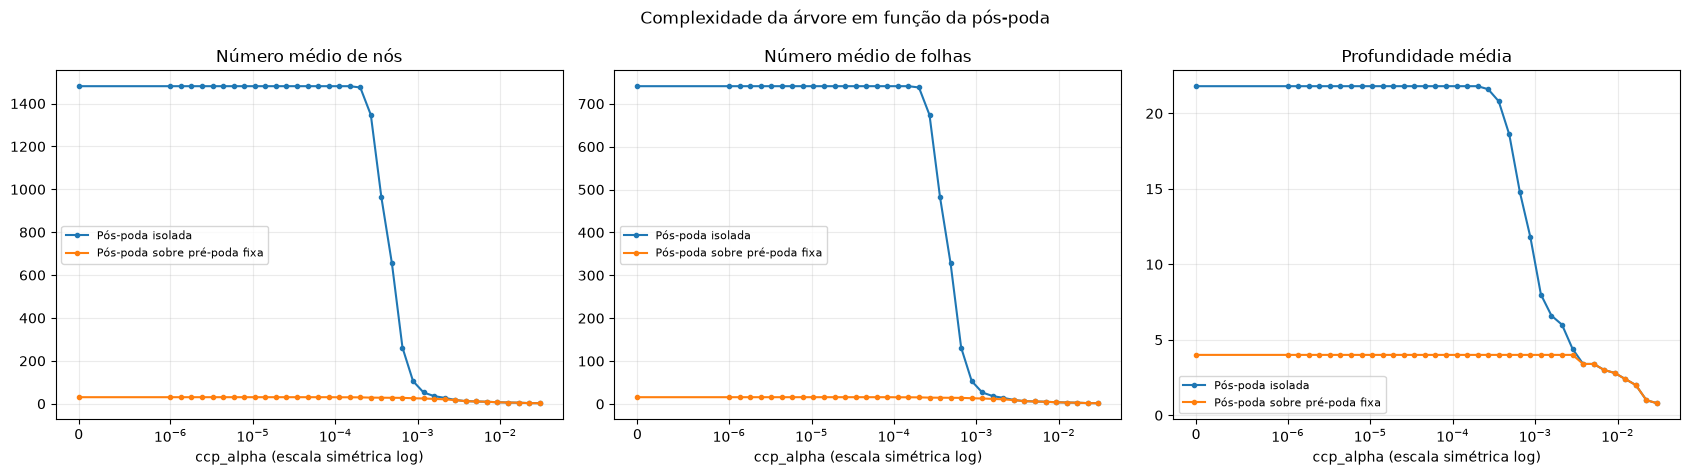

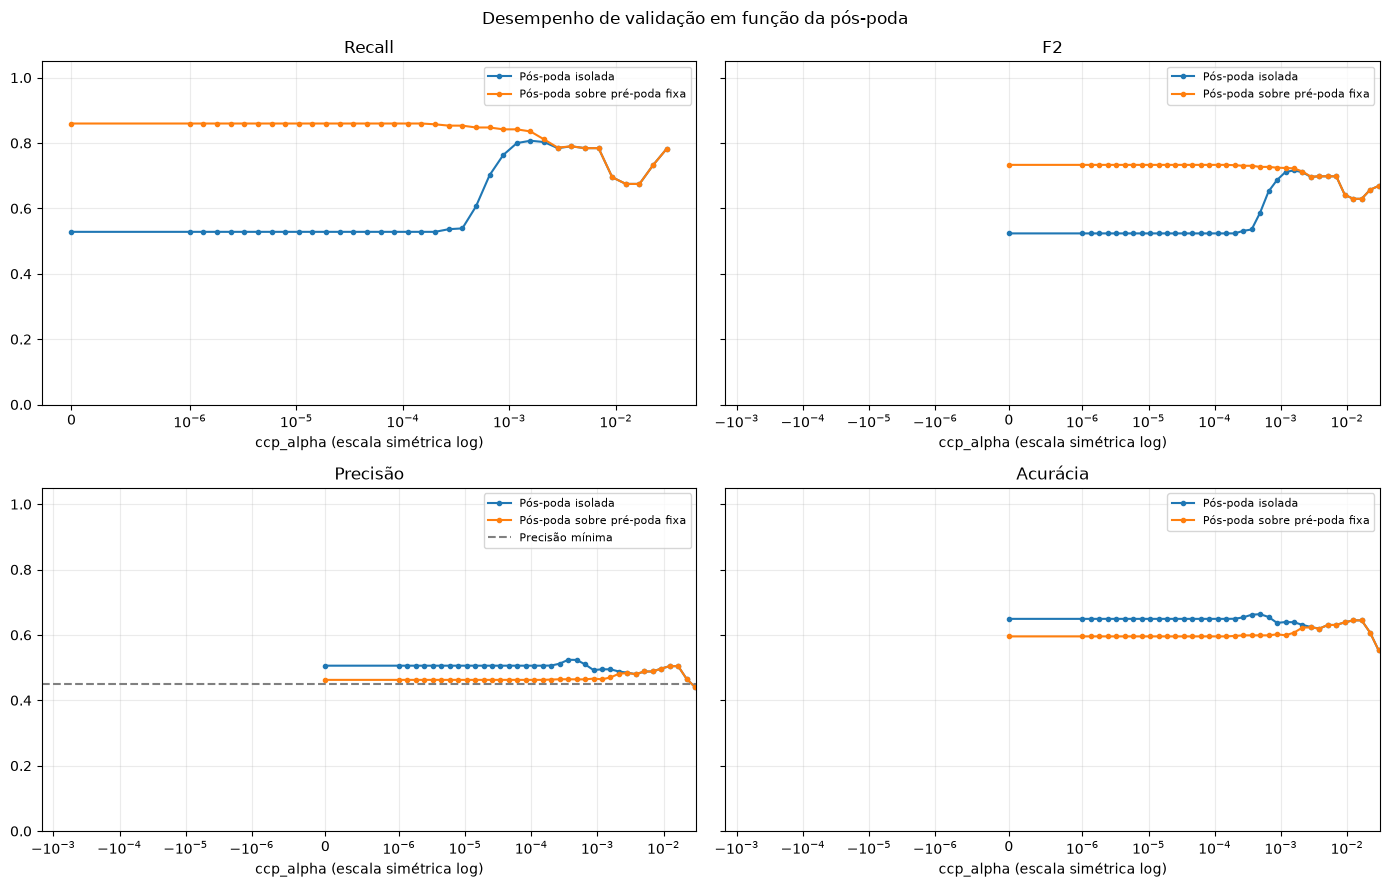

In [16]:
# Gráficos estruturais: nós, folhas e profundidade contra ccp_alpha.
fig, axs = plt.subplots(1, 3, figsize=(17, 4.8))
for cenario, parte in df_alpha_resumo.groupby('cenario', sort=False):
    parte = parte.sort_values('ccp_alpha')
    for ax, coluna, titulo in zip(
        axs, ['nos', 'folhas', 'profundidade'],
        ['Número médio de nós', 'Número médio de folhas', 'Profundidade média']
    ):
        ax.plot(parte['ccp_alpha'], parte[coluna], marker='.', label=cenario)
        ax.set_title(titulo)
for ax in axs.ravel():
    ax.set_xscale('symlog', linthresh=1e-6)
    ax.set_xlabel('ccp_alpha (escala simétrica log)')
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
fig.suptitle('Complexidade da árvore em função da pós-poda')
plt.tight_layout()
plt.savefig(PASTA_INTERNA / 'alpha_nos_folhas_profundidade.png', dpi=200, bbox_inches='tight')
plt.show()

# Gráficos das métricas, para observar o custo/benefício de simplificar a árvore.
fig, axs = plt.subplots(2, 2, figsize=(14, 9), sharey=True)
for cenario, parte in df_alpha_resumo.groupby('cenario', sort=False):
    parte = parte.sort_values('ccp_alpha')
    for ax, coluna, titulo in zip(
        axs.ravel(), ['recall', 'f2', 'precisao', 'acuracia'], ['Recall', 'F2', 'Precisão', 'Acurácia']
    ):
        ax.plot(parte['ccp_alpha'], parte[coluna], marker='.', label=cenario)
        ax.set_title(titulo)
for ax in axs.ravel():
    ax.set_xscale('symlog', linthresh=1e-6)
    ax.set_xlabel('ccp_alpha (escala simétrica log)')
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
if PRECISAO_MINIMA is not None:
    axs[1, 0].axhline(PRECISAO_MINIMA, ls='--', color='gray', label='Precisão mínima')
    axs[1, 0].legend(fontsize=8)
fig.suptitle('Desempenho de validação em função da pós-poda')
plt.tight_layout()
plt.savefig(PASTA_INTERNA / 'alpha_recall_f2_precisao_acuracia.png', dpi=200, bbox_inches='tight')
plt.show()

**10. Congelar um candidato por estratégia antes do teste final**

Observe primeiro os gráficos e tabelas da segunda validação. Em ESCOLHA_FINAL, selecione um candidato por estratégia: aquele escolhido pelo melhor recall ou pelo melhor F2 na primeira CV. Essas escolhas podem ser apoiadas pelo diagnóstico da segunda CV; porém, nenhuma usa X_test/`y_test`.

Abaixo ficam inicialmente os candidatos por recall, para preservar a configuração da busca do notebook enviado. Troque a chave por _f2 caso deseje apresentar a alternativa correspondente no teste final.

In [17]:
# Congele a escolha antes do conjunto de TESTE. Aliases recall/F2 são resolvidos.
ESCOLHA_FINAL = {
    'pre_poda': 'pre_poda_recall',  # ou 'pre_poda_f2'
    'pos_poda': 'pos_poda_recall',  # ou 'pos_poda_f2'
    'hibrida': 'hibrida_recall',    # ou 'hibrida_f2'
}

configuracoes = {'baseline': dict(candidatos_duas_metricas['baseline'])}
ESCOLHA_FINAL_RESOLVIDA = {}
for estrategia, nome in ESCOLHA_FINAL.items():
    chave = ALIAS_CANDIDATOS.get(nome, nome)
    if chave not in candidatos_duas_metricas:
        print(f'{estrategia}: candidato {nome} indisponível (sem trial elegível).')
        continue
    configuracoes[estrategia] = dict(candidatos_duas_metricas[chave])
    ESCOLHA_FINAL_RESOLVIDA[estrategia] = chave

print('Configurações congeladas (sem consultar os 30% de teste):')
for estrategia, config in configuracoes.items():
    print(f'  {NOMES_ESTRATEGIAS[estrategia]}: {rotulo_modelo(ESCOLHA_FINAL_RESOLVIDA.get(estrategia, "baseline"))}')

pasta_escolhas = PASTA_INTERNA
(pasta_escolhas / 'configuracoes_congeladas.json').write_text(
    json.dumps(configuracoes, indent=2, ensure_ascii=False), encoding='utf-8'
)

Configurações congeladas (sem consultar os 30% de teste):
  Baseline (sem poda): Baseline (sem poda) · Referência · limiar=0.24
  Pré-poda isolada: Pré-poda isolada · Melhor recall e Melhor F2 · limiar=0.24 · trial #87
  Pós-poda isolada: Pós-poda isolada · Melhor recall e Melhor F2 · limiar=0.24 · trial #36
  Poda híbrida (pré + pós): Poda híbrida (pré + pós) · Melhor recall e Melhor F2 · limiar=0.24 · trial #74


1949

**11. Comparação INTERNA dos quatro modelos congelados — segunda CV (CV2)**

Baseline, pré-poda, pós-poda e híbrida com o limiar definido neste estudo. Métricas médias, desvios e diferenças em relação ao baseline, calculados nos mesmos folds. Se duas estratégias tiverem a mesma configuração, o empate será destacado em vez de produzir gráficos duplicados.

INTERNA — comparação dos quatro congelados na CV2:


,estrategia,modelo,limiar,trial,nos,folhas,profundidade,folds_precisao_minima,recall,recall_dp,f2,f2_dp,precisao,precisao_dp,acuracia,acuracia_dp,delta_recall_pp,delta_f2_pp,delta_precisao_pp,delta_acuracia_pp
0,baseline,baseline,0.24,NaN,1475.8,738.4,23.6,4,0.5113,0.0297,0.5066,0.0293,0.4894,0.0343,0.6374,0.0243,0.0000,0.0000,0.0000,0.0000
1,pre_poda,pre_poda_recall,0.24,87.0,30.2,15.6,4.0,3,0.8476,0.0576,0.7253,0.0377,0.4610,0.0222,0.5943,0.0285,33.6302,21.8638,-2.8340,-4.3074
2,pos_poda,pos_poda_recall,0.24,36.0,28.2,14.6,5.0,3,0.8249,0.0586,0.7163,0.0393,0.4712,0.0287,0.6084,0.0370,31.3630,20.9661,-1.8212,-2.9007
3,hibrida,hibrida_recall,0.24,74.0,30.2,15.6,4.0,3,0.8476,0.0576,0.7253,0.0377,0.4610,0.0222,0.5943,0.0285,33.6302,21.8638,-2.8340,-4.3074


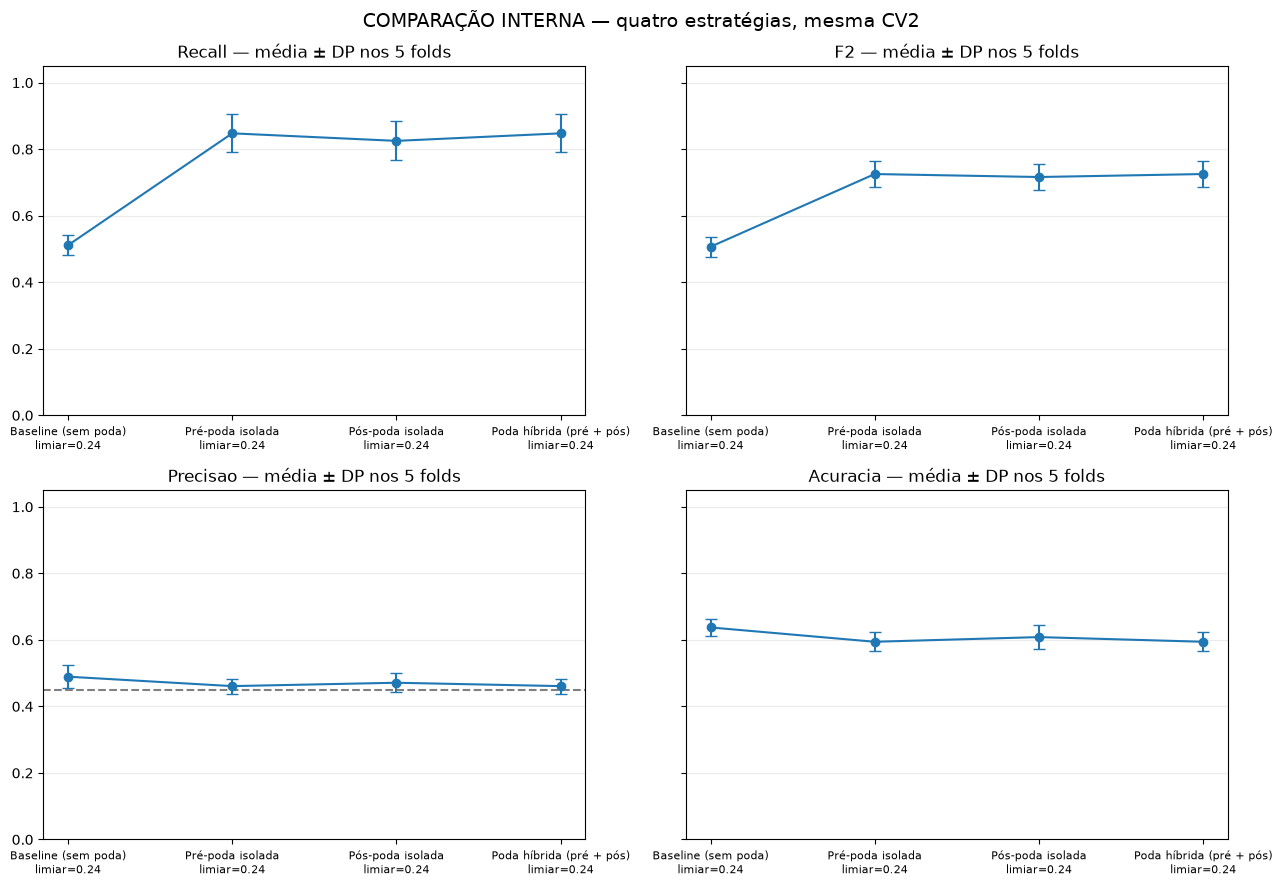

In [18]:
# Resumo INTERNO final: quatro estratégias do mesmo experimento na CV2.
# As matrizes OOF dos destaques já estão na seção 8.1; aqui basta UMA comparação.
if 'configuracoes' not in globals():
    raise RuntimeError('Execute a seção 10 para congelar as configurações.')
if 'df_cv2_folds' not in globals():
    df_cv2_folds = pd.read_csv(PASTA_INTERNA / 'segunda_validacao_por_fold.csv')

linhas = []
for estrategia, config in configuracoes.items():
    nome = ESCOLHA_FINAL_RESOLVIDA.get(estrategia, 'baseline')
    dados = df_cv2_folds.loc[df_cv2_folds['modelo'] == nome]
    if dados.empty:
        raise ValueError(f'Sem métricas CV2 para {nome}; execute a seção 8.')
    linha = {
        'estrategia': estrategia,
        'modelo': nome,
        'limiar': float(config['limiar']),
        'trial': config['trial'],
        'nos': dados['nos'].mean(),
        'folhas': dados['folhas'].mean(),
        'profundidade': dados['profundidade'].mean(),
        'folds_precisao_minima': (
            int((dados['precisao'] >= PRECISAO_MINIMA).sum())
            if PRECISAO_MINIMA is not None else np.nan
        ),
    }
    for metrica in ['recall', 'f2', 'precisao', 'acuracia']:
        linha[metrica] = dados[metrica].mean()
        linha[f'{metrica}_dp'] = dados[metrica].std(ddof=1)
    linhas.append(linha)

df_interna_cv2 = pd.DataFrame(linhas)
df_interna_cv2.to_csv(PASTA_INTERNA / 'comparacao_interna_quatro_cv2.csv', index=False)
base = df_interna_cv2.loc[df_interna_cv2['estrategia'] == 'baseline'].iloc[0]
for metrica in ['recall', 'f2', 'precisao', 'acuracia']:
    df_interna_cv2[f'delta_{metrica}_pp'] = 100 * (
        df_interna_cv2[metrica] - base[metrica]
    )
print('INTERNA — comparação dos quatro congelados na CV2:')
display(df_interna_cv2.round(4))

# Se duas estratégias chegarem à mesma árvore e limiar, explicitar o empate.
for a, ca in configuracoes.items():
    for b, cb in configuracoes.items():
        if a < b and ca['parametros'] == cb['parametros'] and ca['limiar'] == cb['limiar']:
            print(f'OBSERVAÇÃO: {a} e {b} possuem configuração idêntica; métricas iguais são esperadas.')

x = np.arange(len(df_interna_cv2))
nomes = [f'{NOMES_ESTRATEGIAS[n]}\nlimiar={l:.2f}'
         for n, l in zip(df_interna_cv2['estrategia'], df_interna_cv2['limiar'])]
fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharey=True)
for ax, metrica in zip(axes.ravel(), ['recall', 'f2', 'precisao', 'acuracia']):
    ax.errorbar(x, df_interna_cv2[metrica].to_numpy(),
                yerr=df_interna_cv2[f'{metrica}_dp'].fillna(0).to_numpy(),
                marker='o', capsize=4)
    ax.set_xticks(x, nomes, fontsize=8)
    ax.set_title(f'{metrica.capitalize()} — média ± DP nos 5 folds')
    ax.set_ylim(0, 1.05)
    ax.grid(axis='y', alpha=0.25)
    if metrica == 'precisao' and PRECISAO_MINIMA is not None:
        ax.axhline(PRECISAO_MINIMA, linestyle='--', color='gray')
fig.suptitle('COMPARAÇÃO INTERNA — quatro estratégias, mesma CV2', fontsize=14)
plt.tight_layout()
plt.savefig(PASTA_INTERNA / 'comparacao_interna_quatro_cv2.png', dpi=220, bbox_inches='tight')
plt.show()

**11.1. COMPARAÇÃO GERAL — seleção de candidatos de TODOS os experimentos**

Busca automaticamente estudos compatíveis no banco Optuna inteiro, não apenas NOME_ESTUDO. Preserva limiares e objetivos de cada experimento. Seleciona por CV1 e deduplica configurações idênticas. Estudos de bases diferentes são deliberadamente excluídos para não misturar resultados incompatíveis.

In [19]:
import hashlib
import optuna
from optuna.trial import TrialState
from optuna_arvore_churn import _assinatura_dados, PREPROCESSAMENTO

PASTA_GERAL = PASTA / 'comparacao_entre_experimentos'
PASTA_GERAL.mkdir(parents=True, exist_ok=True)
PRECISAO_GLOBAL = None  # inclui todos os estudos; use 0.50 se quiser filtrar
ESTRATEGIAS = ('pre_poda', 'pos_poda', 'hibrida')
NOMES_ESTRATEGIAS_GERAL = {
    'baseline': 'Baseline', 'pre_poda': 'Pré-poda',
    'pos_poda': 'Pós-poda', 'hibrida': 'Híbrida'
}
DB_GERAL = PASTA / 'estudos_optuna_categorico.db'
if not DB_GERAL.exists():
    raise FileNotFoundError(f'Banco dos experimentos não encontrado: {DB_GERAL}')
STORAGE_GERAL = f'sqlite:///{DB_GERAL.resolve().as_posix()}'
ASSINATURA_ATUAL = _assinatura_dados(X_train, y_train)

# Descobre todos os grupos de estudo salvos; nunca usa NOME_ESTUDO como filtro.
sumarios = optuna.study.get_all_study_summaries(storage=STORAGE_GERAL)
grupos = {}
for resumo in sumarios:
    nome = resumo.study_name
    for sufixo in ESTRATEGIAS:
        if nome.endswith('_' + sufixo):
            experimento = nome[:-len(sufixo)-1]
            grupos.setdefault(experimento, {})[sufixo] = nome
            break

catalogo_global = []
baselines_global = []
experimentos_aceitos = []
experimentos_ignorados = []
for experimento, grupo in sorted(grupos.items()):
    if set(grupo) != set(ESTRATEGIAS):
        experimentos_ignorados.append((experimento, 'estratégias incompletas'))
        continue
    estudos_grupo = {
        e: optuna.load_study(study_name=grupo[e], storage=STORAGE_GERAL)
        for e in ESTRATEGIAS
    }
    protocolos = [s.user_attrs for s in estudos_grupo.values()]
    chaves = ('dataset_fingerprint', 'preprocessing', 'n_splits',
              'limiar', 'precisao_minima', 'objetivo')
    if any(any(a.get(k) != protocolos[0].get(k) for k in chaves)
           for a in protocolos[1:]):
        experimentos_ignorados.append((experimento, 'protocolos divergentes entre estratégias'))
        continue
    meta = protocolos[0]
    if (meta.get('dataset_fingerprint') != ASSINATURA_ATUAL or
        meta.get('preprocessing') != PREPROCESSAMENTO):
        experimentos_ignorados.append((experimento, 'dataset ou pré-processamento incompatível'))
        continue
    if int(meta.get('n_splits', 0)) != 5:
        experimentos_ignorados.append((experimento, 'número de folds distinto de cinco'))
        continue
    limiar_estudo = float(meta['limiar'])
    experimentos_aceitos.append(experimento)
    for estrategia, estudo in estudos_grupo.items():
        for trial in estudo.trials:
            if (trial.state != TrialState.COMPLETE or trial.value is None or
                    not trial.user_attrs.get('elegivel') or
                    'parametros_arvore' not in trial.user_attrs):
                continue
            reg = {
                'experimento': experimento,
                'estrategia': estrategia,
                'trial': int(trial.number),
                'limiar': limiar_estudo,
                'objetivo_estudo': meta.get('objetivo'),
                'precisao_minima_estudo': meta.get('precisao_minima'),
                'preprocessamento': meta.get('preprocessing'),
                'recall_cv1': float(trial.user_attrs['recall_churn']),
                'f2_cv1': float(trial.user_attrs['f2_churn']),
                'precisao_cv1': float(trial.user_attrs['precisao_churn']),
                'acuracia_cv1': float(trial.user_attrs['acuracia']),
                'parametros': dict(trial.user_attrs['parametros_arvore']),
            }
            reg['passa_precisao_global'] = (
                PRECISAO_GLOBAL is None or reg['precisao_cv1'] >= PRECISAO_GLOBAL
            )
            catalogo_global.append(reg)
    resumo_csv = PASTA / f'resumo_{experimento}.csv'
    if resumo_csv.exists():
        tabela = pd.read_csv(resumo_csv)
        base = tabela.loc[tabela['estrategia'] == 'baseline']
        if not base.empty:
            base = base.iloc[0]
            baselines_global.append({
                'experimento': experimento, 'estrategia': 'baseline',
                'trial': None, 'limiar': limiar_estudo,
                'objetivo_estudo': meta.get('objetivo'),
                'precisao_minima_estudo': meta.get('precisao_minima'),
                'recall_cv1': float(base['recall_churn']),
                'f2_cv1': float(base['f2_churn']),
                'precisao_cv1': float(base['precisao_churn']),
                'acuracia_cv1': float(base['acuracia']),
                'parametros': parametros_baseline(),
                'passa_precisao_global': True,
            })

print(f'Experimentos compatíveis encontrados: {len(experimentos_aceitos)}')
print('Experimentação disponível:', ', '.join(experimentos_aceitos) or '(nenhuma)')
if experimentos_ignorados:
    print('Ignorados (não devem ser misturados):')
    for nome, motivo in experimentos_ignorados:
        print(f'  - {nome}: {motivo}')
if len(experimentos_aceitos) < 2:
    raise RuntimeError(
        'Comparação GERAL exige ao menos dois experimentos compatíveis. '
        'Não reutilize estudos de outro dataset; rode e salve novos estudos na mesma base.'
    )
if globals().get('HISTORICO_COM_VAZAMENTO', False):
    print('ALERTA: análise histórica sobre base com indício de leakage temporal.')

if not catalogo_global:
    raise RuntimeError('Não existem trials elegíveis compatíveis no SQLite.')

catalogo_df = pd.DataFrame(catalogo_global)
# Catálogo COMPLETO: aqui constam todos os trials elegíveis de todos os estudos.
catalogo_csv = catalogo_df.drop(columns=['parametros'])
catalogo_csv.to_csv(PASTA_GERAL / 'catalogo_todos_trials.csv', index=False)
print('Resumo: melhores candidatos da CV1 POR EXPERIMENTO (com ênfase nos 2 critérios).')

# Para cada estudo: melhor recall e melhor F2 dentre todas as três estratégias,
# respeitando a mesma precisão global. Isto NÃO usa a segunda CV para escolher.
selecoes = []
for experimento, parte in catalogo_df.groupby('experimento', sort=True):
    elegiveis = parte.loc[parte['passa_precisao_global']]
    if elegiveis.empty:
        print(f'{experimento}: nenhuma configuração alcança precisão global exigida.')
        continue
    for metrica, rotulo in [('recall_cv1', 'Melhor recall'),
                            ('f2_cv1', 'Melhor F2')]:
        vencedor = elegiveis.sort_values(
            [metrica, 'precisao_cv1'], ascending=[False, False]
        ).iloc[0].to_dict()
        vencedor['motivo_selecao'] = rotulo
        selecoes.append(vencedor)

# Baselines distintos por limiar: referência, não competem na otimização.
for b in baselines_global:
    selecoes.append(dict(b, motivo_selecao='Referência'))

# Une repetições (mesmos hiperparâmetros + mesmo limiar), mas conserva
# a origem e as duas razões de seleção na tabela, se forem coincidentes.
modelos_globais = {}
for reg in selecoes:
    assinatura_config = json.dumps(
        {'parametros': reg['parametros'], 'limiar': round(float(reg['limiar']), 8)},
        sort_keys=True, default=str,
    )
    chave = hashlib.sha256(assinatura_config.encode()).hexdigest()[:16]
    if chave not in modelos_globais:
        modelos_globais[chave] = dict(reg, origens=[], motivos=[], estrategias_origem=[])
    modelos_globais[chave]['origens'].append(reg['experimento'])
    modelos_globais[chave]['estrategias_origem'].append(reg['estrategia'])
    modelos_globais[chave]['motivos'].append(reg['motivo_selecao'])

candidatos_globais = {}
linhas_manifesto = []
for i, reg in enumerate(modelos_globais.values(), 1):
    codigo = f'G{i:02d}'
    origens = ', '.join(sorted(set(reg['origens'])))
    motivos = ' + '.join(sorted(set(reg['motivos'])))
    estrategias_origem = ', '.join(sorted(set(reg['estrategias_origem'])))
    rotulo = (f'{codigo} | {origens} | {NOMES_ESTRATEGIAS_GERAL[reg["estrategia"]]} '
              f'| {motivos} | limiar={reg["limiar"]:.2f}')
    candidatos_globais[codigo] = {
        'parametros': dict(reg['parametros']),
        'limiar': float(reg['limiar']),
        'rotulo': rotulo,
        'experimentos': origens,
        'estrategias_origem': estrategias_origem,
        'criterios': motivos,
    }
    linhas_manifesto.append({
        'codigo': codigo, 'experimentos': origens,
        'estrategia': reg['estrategia'], 'estrategias_origem': estrategias_origem, 'selecao': motivos,
        'limiar': float(reg['limiar']),
        'recall_cv1': reg['recall_cv1'], 'f2_cv1': reg['f2_cv1'],
        'precisao_cv1': reg['precisao_cv1'],
        'acuracia_cv1': reg['acuracia_cv1'],
        'trial_origem': reg['trial'],
        'rotulo': rotulo,
        'parametros': json.dumps(reg['parametros'], sort_keys=True),
    })

df_global_cv1 = pd.DataFrame(linhas_manifesto)
df_global_cv1.to_csv(PASTA_GERAL / 'candidatos_entre_experimentos_cv1.csv', index=False)
display(df_global_cv1.drop(columns=['parametros']).round(4))

print("A comparação visual GERAL será exibida na seção 11.2, após a CV2 comum.")

Experimentos compatíveis encontrados: 9
Experimentação disponível: E1_t030_f2_prec050_v1, E2_t024_f2_prec050_v1, E3_t020_f2_prec045_v1, E3_t024_f2_prec045_v1, E3_t050_f2_prec040_v1, E3_t050_f2_prec050_v1, E4_t020_rec_prec045_v1, E4_t024_rec_prec050_v1, E4_t030_rec_prec050_v1
Ignorados (não devem ser misturados):
  - E2_t024_rec_prec050_v1: estratégias incompletas
  - E2_t030_f2_prec050_v1: estratégias incompletas
  - E3_t024_f2_prec050_v1: estratégias incompletas
Resumo: melhores candidatos da CV1 POR EXPERIMENTO (com ênfase nos 2 critérios).


,codigo,experimentos,estrategia,estrategias_origem,selecao,limiar,recall_cv1,f2_cv1,precisao_cv1,acuracia_cv1,trial_origem,rotulo
0,G01,E1_t030_f2_prec050_v1,pre_poda,pre_poda,Melhor F2 + Melhor recall,0.30,0.7715,0.7039,0.5234,0.6690,18.0,G01 | E1_t030_f2_prec050_v1 | Pré-poda | Melho...
1,G02,E2_t024_f2_prec050_v1,pre_poda,pre_poda,Melhor F2 + Melhor recall,0.24,0.7772,0.7002,0.5027,0.6480,75.0,G02 | E2_t024_f2_prec050_v1 | Pré-poda | Melho...
2,G03,E3_t020_f2_prec045_v1,hibrida,hibrida,Melhor F2 + Melhor recall,0.20,0.8922,0.7531,0.4645,0.5969,81.0,G03 | E3_t020_f2_prec045_v1 | Híbrida | Melhor...
3,G04,E3_t024_f2_prec045_v1,pre_poda,pre_poda,Melhor F2 + Melhor recall,0.24,0.8598,0.7332,0.4625,0.5955,87.0,G04 | E3_t024_f2_prec045_v1 | Pré-poda | Melho...
4,G05,"E3_t050_f2_prec040_v1, E3_t050_f2_prec050_v1",pre_poda,pre_poda,Melhor recall,0.50,0.5746,0.5794,0.6041,0.7152,0.0,"G05 | E3_t050_f2_prec040_v1, E3_t050_f2_prec05..."
5,G06,"E3_t050_f2_prec040_v1, E3_t050_f2_prec050_v1",hibrida,hibrida,Melhor F2,0.50,0.5737,0.5797,0.6098,0.7186,37.0,"G06 | E3_t050_f2_prec040_v1, E3_t050_f2_prec05..."
6,G07,E4_t020_rec_prec045_v1,pre_poda,pre_poda,Melhor F2 + Melhor recall,0.20,0.8890,0.7466,0.4558,0.5840,2.0,G07 | E4_t020_rec_prec045_v1 | Pré-poda | Melh...
7,G08,E4_t024_rec_prec050_v1,pre_poda,pre_poda,Melhor F2 + Melhor recall,0.24,0.7569,0.6882,0.5061,0.6512,18.0,G08 | E4_t024_rec_prec050_v1 | Pré-poda | Melh...
8,G09,E4_t030_rec_prec050_v1,pre_poda,pre_poda,Melhor recall,0.30,0.7690,0.6988,0.5142,0.6595,26.0,G09 | E4_t030_rec_prec050_v1 | Pré-poda | Melh...
9,G10,E4_t030_rec_prec050_v1,pre_poda,pre_poda,Melhor F2,0.30,0.7666,0.7012,0.5252,0.6704,21.0,G10 | E4_t030_rec_prec050_v1 | Pré-poda | Melh...


A comparação visual GERAL será exibida na seção 11.2, após a CV2 comum.


**11.2. COMPARAÇÃO GERAL — reavaliação dos estudos diferentes na MESMA CV2**

Usa folds comuns para comparar modelos originados de experimentos distintos, com seus limiares originais. Produz um ranking completo e um gráfico de trade-off. Não é a comparação interna das quatro podas, nem utiliza o teste reservado.

COMPARAÇÃO GERAL: candidatos originados de estudos diferentes, sem duplicatas.


,codigo,experimentos,estrategias_origem,selecao,limiar,recall_cv1,recall_cv2,f2_cv1,f2_cv2,precisao_cv1,precisao_cv2,acuracia_cv1,acuracia_cv2,nos_cv2,profundidade_cv2
6,G07,E4_t020_rec_prec045_v1,pre_poda,Melhor F2 + Melhor recall,0.20,0.8890,0.8906,0.7466,0.7494,0.4558,0.4610,0.5840,0.5892,53.4,5.0
2,G03,E3_t020_f2_prec045_v1,hibrida,Melhor F2 + Melhor recall,0.20,0.8922,0.8744,0.7531,0.7399,0.4645,0.4591,0.5969,0.5894,82.2,6.0
3,G04,E3_t024_f2_prec045_v1,pre_poda,Melhor F2 + Melhor recall,0.24,0.8598,0.8622,0.7332,0.7391,0.4625,0.4718,0.5955,0.6075,30.6,4.0
8,G09,E4_t030_rec_prec050_v1,pre_poda,Melhor recall,0.30,0.7690,0.7990,0.6988,0.7102,0.5142,0.4923,0.6595,0.6362,57.8,6.6
0,G01,E1_t030_f2_prec050_v1,pre_poda,Melhor F2 + Melhor recall,0.30,0.7715,0.7933,0.7039,0.7080,0.5234,0.4959,0.6690,0.6405,47.0,6.2
9,G10,E4_t030_rec_prec050_v1,pre_poda,Melhor F2,0.30,0.7666,0.7933,0.7012,0.7077,0.5252,0.4949,0.6704,0.6394,53.8,6.4
1,G02,E2_t024_f2_prec050_v1,pre_poda,Melhor F2 + Melhor recall,0.24,0.7772,0.7933,0.7002,0.7062,0.5027,0.4955,0.6480,0.6365,85.0,8.8
7,G08,E4_t024_rec_prec050_v1,pre_poda,Melhor F2 + Melhor recall,0.24,0.7569,0.7487,0.6882,0.6820,0.5061,0.5049,0.6512,0.6492,121.0,10.6
5,G06,"E3_t050_f2_prec040_v1, E3_t050_f2_prec050_v1",hibrida,Melhor F2,0.50,0.5737,0.5567,0.5797,0.5634,0.6098,0.5949,0.7186,0.7077,56.2,5.0
4,G05,"E3_t050_f2_prec040_v1, E3_t050_f2_prec050_v1",pre_poda,Melhor recall,0.50,0.5746,0.5445,0.5794,0.5511,0.6041,0.5876,0.7152,0.7005,59.8,5.0


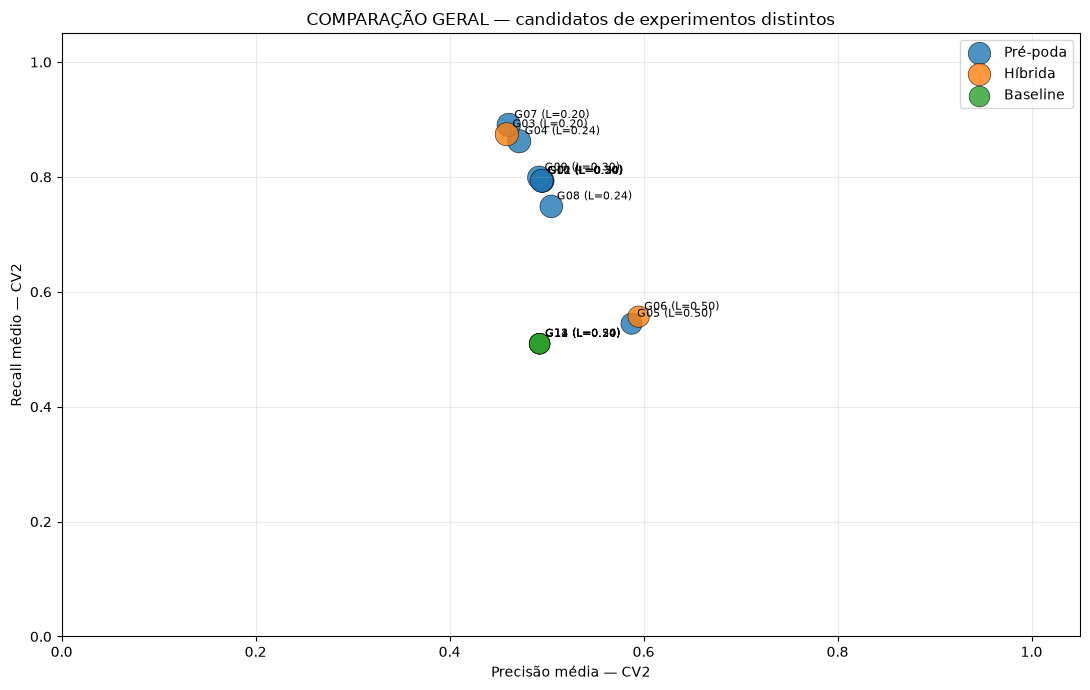

As métricas F2 e acurácia de TODOS os candidatos estão na tabela e no CSV.
CV2 usa novos folds dos mesmos 70%; NÃO é teste externo independente.


In [20]:
from sklearn.tree import DecisionTreeClassifier

SEMENTE_GERAL_CV2 = 2027
CV_GERAL = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE_GERAL_CV2)
linhas_global_cv2 = []
linhas_global_oof = []

# Reajusta o pré-processador DENTRO de cada fold, reutilizando apenas as
# transformações do próprio fold. Nunca transforma com um imputador global.
for fold, (idx_tr, idx_val) in enumerate(CV_GERAL.split(X_train, y_train), 1):
    assert not set(idx_tr).intersection(set(idx_val)), 'Fold contém sobreposição!'
    X_tr, X_val = X_train.iloc[idx_tr], X_train.iloc[idx_val]
    y_tr, y_val = y_train.iloc[idx_tr], y_train.iloc[idx_val]
    preparador = criar_preprocessador()
    X_tr_p = preparador.fit_transform(X_tr)
    X_val_p = preparador.transform(X_val)

    for codigo, config in candidatos_globais.items():
        params = dict(config['parametros'])
        params.pop('random_state', None)
        params.pop('categorical_features', None)
        modelo = DecisionTreeClassifier(
            categorical_features='from_dtype', random_state=42, **params
        )
        modelo.fit(X_tr_p, y_tr)
        indice = list(modelo.classes_).index(1)
        probas = modelo.predict_proba(X_val_p)[:, indice]
        pred = (probas >= config['limiar']).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_val, pred, labels=[0,1]).ravel()
        linhas_global_cv2.append({
            'codigo': codigo, 'fold': fold, 'limiar': config['limiar'],
            'recall': recall_score(y_val, pred, zero_division=0),
            'precisao': precision_score(y_val, pred, zero_division=0),
            'f2': fbeta_score(y_val, pred, beta=2, zero_division=0),
            'acuracia': accuracy_score(y_val, pred),
            'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp),
            'nos': int(modelo.tree_.node_count),
            'folhas': int(modelo.get_n_leaves()),
            'profundidade': int(modelo.get_depth()),
        })
        for pos, real, previsto in zip(idx_val, y_val.to_numpy(), pred):
            linhas_global_oof.append({
                'codigo': codigo, 'fold': fold, 'indice_treino': int(pos),
                'y_real': int(real), 'y_previsto': int(previsto),
            })

df_global_cv2_folds = pd.DataFrame(linhas_global_cv2)
df_global_cv2_oof = pd.DataFrame(linhas_global_oof)
for codigo, parte in df_global_cv2_oof.groupby('codigo'):
    # Exatamente uma previsão fora de treino para cada linha de X_train.
    if (len(parte) != len(X_train) or
        len(set(parte.indice_treino)) != len(X_train) or
        set(parte.indice_treino) != set(range(len(X_train)))):
        raise ValueError(f'CV2 global inconsistente para {codigo}')

resumo_global = df_global_cv2_folds.groupby('codigo', as_index=False).agg(
    recall_cv2=('recall', 'mean'), recall_dp=('recall', 'std'),
    f2_cv2=('f2', 'mean'), f2_dp=('f2', 'std'),
    precisao_cv2=('precisao', 'mean'), precisao_dp=('precisao', 'std'),
    acuracia_cv2=('acuracia', 'mean'), acuracia_dp=('acuracia', 'std'),
    nos_cv2=('nos', 'mean'), folhas_cv2=('folhas', 'mean'),
    profundidade_cv2=('profundidade', 'mean'),
)
df_global_comparacao = df_global_cv1.merge(resumo_global, on='codigo', validate='one_to_one')
df_global_cv2_folds.to_csv(PASTA_GERAL / 'cv2_por_fold_entre_experimentos.csv', index=False)
df_global_cv2_oof.to_csv(PASTA_GERAL / 'predicoes_oof_entre_experimentos.csv', index=False)
df_global_comparacao.to_csv(PASTA_GERAL / 'comparacao_geral_cv1_cv2.csv', index=False)
print('COMPARAÇÃO GERAL: candidatos originados de estudos diferentes, sem duplicatas.')
display(df_global_comparacao[[
    'codigo', 'experimentos', 'estrategias_origem', 'selecao', 'limiar',
    'recall_cv1', 'recall_cv2', 'f2_cv1', 'f2_cv2',
    'precisao_cv1', 'precisao_cv2', 'acuracia_cv1', 'acuracia_cv2',
    'nos_cv2', 'profundidade_cv2',
]].sort_values('f2_cv2', ascending=False).round(4))

# Uma visualização GERAL: trade-off após reavaliação em folds comuns.
fig, ax = plt.subplots(figsize=(11, 7))
for estrategia, dados in df_global_comparacao.groupby('estrategia', sort=False):
    ax.scatter(
        dados['precisao_cv2'], dados['recall_cv2'],
        s=90 + 260*dados['f2_cv2'], alpha=.8,
        label=NOMES_ESTRATEGIAS_GERAL[estrategia], edgecolors='black', linewidth=.45
    )
for row in df_global_comparacao.itertuples():
    ax.annotate(f'{row.codigo} (L={row.limiar:.2f})',
                (row.precisao_cv2, row.recall_cv2), xytext=(4,5),
                textcoords='offset points', fontsize=8)
if PRECISAO_GLOBAL is not None:
    ax.axvline(PRECISAO_GLOBAL, ls='--', color='gray')
ax.set(xlabel='Precisão média — CV2', ylabel='Recall médio — CV2',
       title='COMPARAÇÃO GERAL — candidatos de experimentos distintos',
       xlim=(0, 1.05), ylim=(0, 1.05))
ax.grid(alpha=.25)
ax.legend(loc='best')
plt.tight_layout()
plt.savefig(PASTA_GERAL / 'tradeoff_entre_experimentos_cv2.png',
            dpi=210, bbox_inches='tight')
plt.show()
print('As métricas F2 e acurácia de TODOS os candidatos estão na tabela e no CSV.')
print('CV2 usa novos folds dos mesmos 70%; NÃO é teste externo independente.')


**11.3. COMPARAÇÃO GERAL — visualização sem esconder candidatos coincidentes**

- O gráfico de dispersão posiciona cada modelo em suas coordenadas reais. Quando dois ou mais candidatos têm métricas iguais ou quase iguais, uma anotação conjunta identifica todos os códigos.
- Os quatro gráficos de barras mostram cada candidato separadamente, incluindo aqueles cujos pontos coincidem. Nenhum limiar ou valor de métrica é alterado para fins de visualização.
- Comparar os resultados CV2 (mesmos 70% em outros folds) ajuda a avaliar estabilidade, mas não substitui o teste reservado.

,codigo,experimentos,estrategia,limiar,recall_cv2,precisao_cv2,f2_cv2,acuracia_cv2
10,G11,"E1_t030_f2_prec050_v1, E4_t030_rec_prec050_v1",baseline,0.30,0.50968,0.49282,0.50591,0.64054
11,G12,"E2_t024_f2_prec050_v1, E3_t024_f2_prec045_v1, ...",baseline,0.24,0.50968,0.49282,0.50591,0.64054
12,G13,"E3_t020_f2_prec045_v1, E4_t020_rec_prec045_v1",baseline,0.20,0.50968,0.49282,0.50591,0.64054
13,G14,"E3_t050_f2_prec040_v1, E3_t050_f2_prec050_v1",baseline,0.50,0.50968,0.49282,0.50591,0.64054
2,G03,E3_t020_f2_prec045_v1,hibrida,0.20,0.87436,0.45907,0.73987,0.58944
5,G06,"E3_t050_f2_prec040_v1, E3_t050_f2_prec050_v1",hibrida,0.50,0.55673,0.59491,0.56342,0.70773
0,G01,E1_t030_f2_prec050_v1,pre_poda,0.30,0.79333,0.49589,0.70800,0.64054
1,G02,E2_t024_f2_prec050_v1,pre_poda,0.24,0.79331,0.49546,0.70624,0.63652
3,G04,E3_t024_f2_prec045_v1,pre_poda,0.24,0.86222,0.47178,0.73910,0.60753
4,G05,"E3_t050_f2_prec040_v1, E3_t050_f2_prec050_v1",pre_poda,0.50,0.54454,0.58763,0.55115,0.70055


Pontos próximos no scatter: G11 (L=0.30), G12 (L=0.24), G13 (L=0.20), G14 (L=0.50)
Pontos próximos no scatter: G01 (L=0.30), G02 (L=0.24)
Previsões OOF idênticas: G11 e G12
Previsões OOF idênticas: G11 e G13
Previsões OOF idênticas: G11 e G14
Previsões OOF idênticas: G12 e G13
Previsões OOF idênticas: G12 e G14
Previsões OOF idênticas: G13 e G14


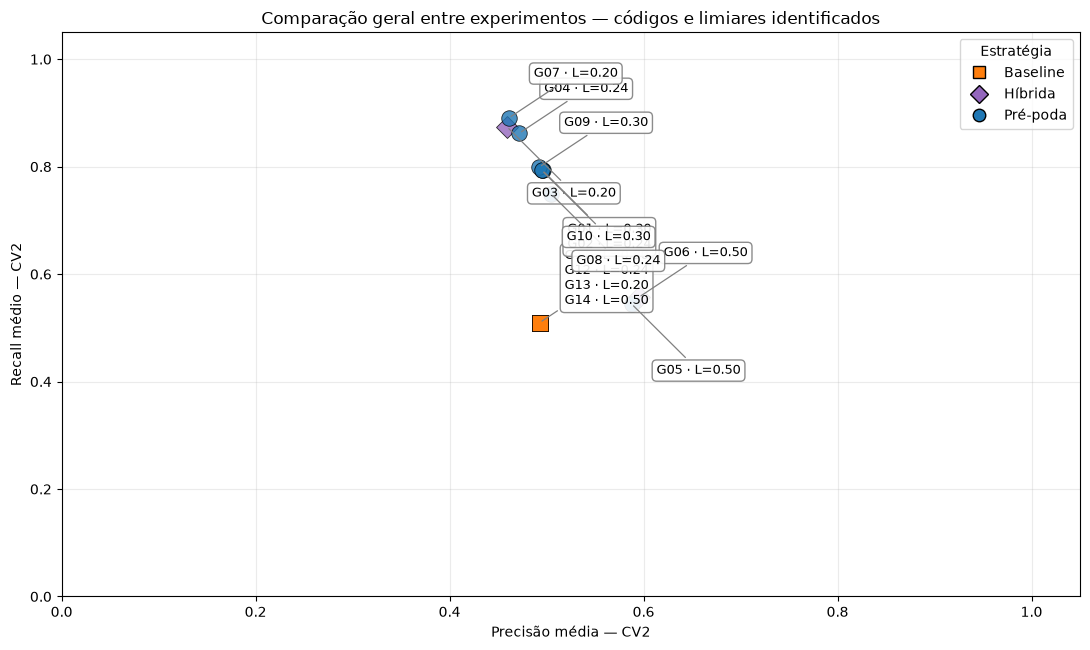

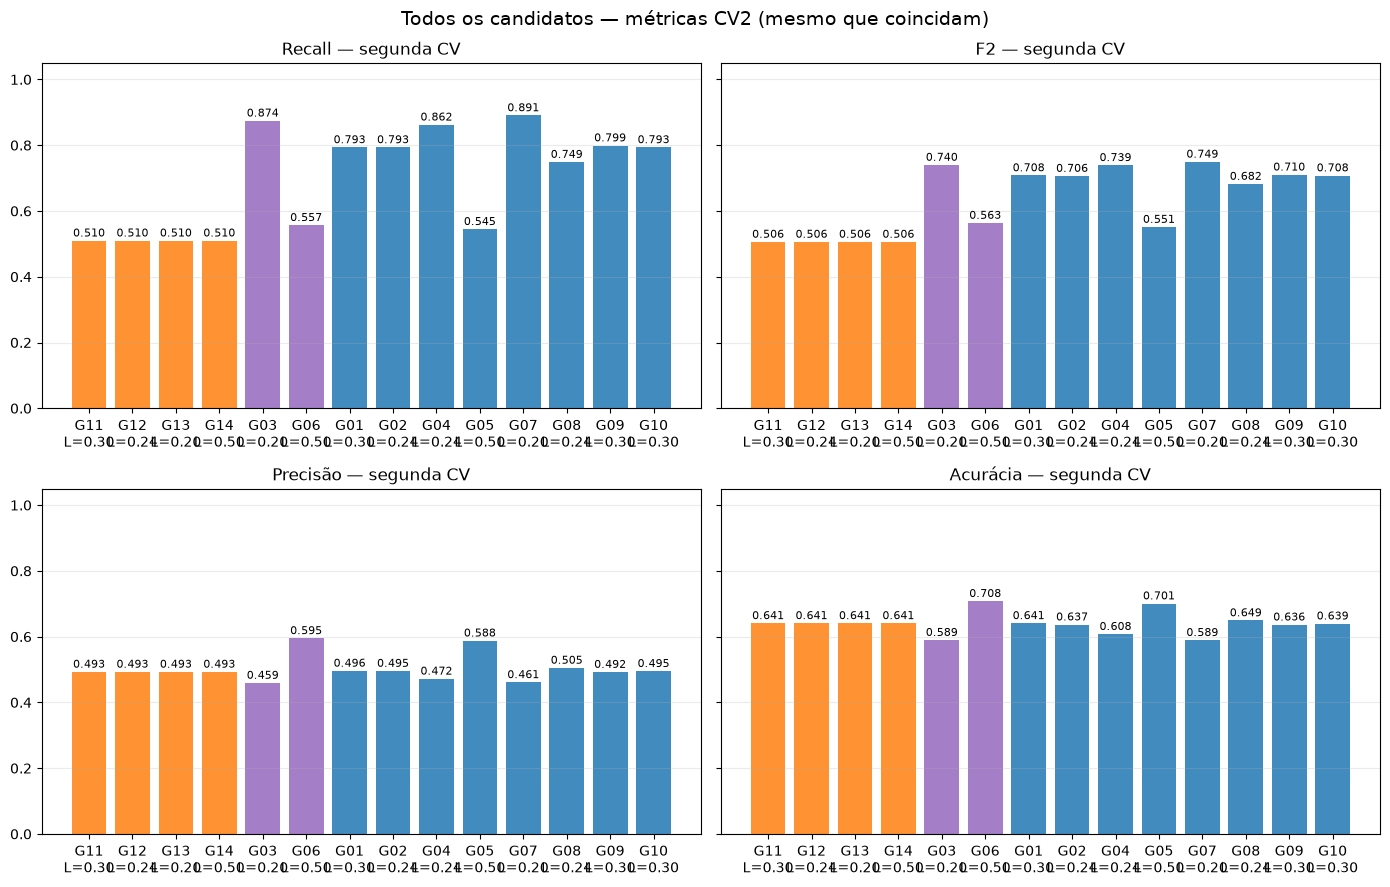

In [21]:
# COMPARAÇÃO GERAL — todos os candidatos, inclusive os sobrepostos.
# A seção 11.2 deve ter sido executada nesta sessão e produzido df_global_comparacao.
# Não consulta o teste e não treina nem ajusta hiperparâmetros.
from matplotlib.lines import Line2D

if 'df_global_comparacao' not in globals() or df_global_comparacao.empty:
    raise RuntimeError('Execute a seção 11.2 para calcular os candidatos da comparação geral.')

vis = df_global_comparacao.copy().sort_values(['estrategia','experimentos','limiar'])
obrigatorias = {'codigo', 'estrategia', 'experimentos', 'limiar',
                'precisao_cv2','recall_cv2','f2_cv2','acuracia_cv2'}
if not obrigatorias.issubset(vis.columns):
    raise ValueError(f'Colunas ausentes: {sorted(obrigatorias - set(vis.columns))}')

nomes_vis = {'baseline': 'Baseline', 'pre_poda': 'Pré-poda',
             'pos_poda': 'Pós-poda', 'hibrida': 'Híbrida'}
cores_vis = {'baseline': 'tab:orange', 'pre_poda': 'tab:blue',
             'pos_poda': 'tab:green', 'hibrida': 'tab:purple'}
marcadores_vis = {'baseline': 's', 'pre_poda': 'o',
                  'pos_poda': '^', 'hibrida': 'D'}

# Mostrar tabela SEM arredondar as métricas antes de descobrir sobreposições.
colunas_vis = ['codigo','experimentos','estrategia','limiar',
               'recall_cv2','precisao_cv2','f2_cv2','acuracia_cv2']
display(vis[colunas_vis].round(5))

# Diagnóstico: mesma combinação de (precisão, recall) com tolerância de 0,005.
# Esta aproximação só AGRUPA RÓTULOS; nunca move pontos do gráfico.
vis['_grupo_x'] = vis['precisao_cv2'].round(2)
vis['_grupo_y'] = vis['recall_cv2'].round(2)
clusters = list(vis.groupby(['_grupo_x','_grupo_y'],sort=False))
for _, parte in clusters:
    if len(parte)>1:
        print('Pontos próximos no scatter:', ', '.join(
            f"{r.codigo} (L={r.limiar:.2f})" for r in parte.itertuples()
        ))

# Diagnóstico mais forte: verificar se as previsões OOF são EXATAMENTE iguais.
if 'df_global_cv2_oof' in globals() and not df_global_cv2_oof.empty:
    previsoes_por_codigo = {}
    for codigo, parte in df_global_cv2_oof.groupby('codigo'):
        previsoes_por_codigo[codigo] = tuple(
            parte.sort_values('indice_treino')['y_previsto'].astype(int).to_numpy()
        )
    codigos = list(previsoes_por_codigo)
    for i, cod_a in enumerate(codigos):
        for cod_b in codigos[i+1:]:
            if previsoes_por_codigo[cod_a] == previsoes_por_codigo[cod_b]:
                print(f'Previsões OOF idênticas: {cod_a} e {cod_b}')

fig, ax = plt.subplots(figsize=(11, 6.6))
for row in vis.itertuples():
    ax.scatter(
        row.precisao_cv2, row.recall_cv2,
        color=cores_vis.get(row.estrategia,'gray'),
        marker=marcadores_vis.get(row.estrategia,'o'),
        s=125, edgecolor='black', linewidth=0.6, alpha=0.80,
        zorder=3,
    )

# Rótulo COMBINADO e seta para cada agrupamento, mesmo quando as
# coordenadas dos pontos são idênticas. O valor de cada ponto é preservado.
for i, (_, parte) in enumerate(clusters):
    x0 = float(parte['precisao_cv2'].mean())
    y0 = float(parte['recall_cv2'].mean())
    texto = '\n'.join(f'{r.codigo} · L={r.limiar:.2f}' for r in parte.itertuples())
    # Distribuir rótulos por quadrante para diminuir colisões.
    desloc_y = 32 if i % 2 == 0 else -48
    ax.annotate(
        texto, (x0,y0), xytext=(18,desloc_y), textcoords='offset points',
        fontsize=9, ha='left', va='center',
        bbox=dict(boxstyle='round,pad=0.35',fc='white',ec='gray',alpha=0.90),
        arrowprops=dict(arrowstyle='-', color='gray', lw=0.9)
    )

legendas = [
    Line2D([0],[0],color='none',marker=marcadores_vis.get(e,'o'),
           markerfacecolor=cores_vis.get(e,'gray'), markeredgecolor='black',
           label=nomes_vis.get(e,e),markersize=9)
    for e in dict.fromkeys(vis['estrategia'])
]
ax.legend(handles=legendas,title='Estratégia',loc='best')
ax.set_xlabel('Precisão média — CV2')
ax.set_ylabel('Recall médio — CV2')
ax.set_title('Comparação geral entre experimentos — códigos e limiares identificados')
ax.set_xlim(0,1.05)
ax.set_ylim(0,1.05)
ax.grid(alpha=.25)
fig.tight_layout()
fig.savefig(PASTA_GERAL / 'tradeoff_entre_experimentos_cv2.png',dpi=220,bbox_inches='tight')
plt.show()

# Complemento: quatro barras POR CANDIDATO, sem ocultar coincidências.
# Códigos iguais aos da tabela e ao gráfico anterior.
fig, axs = plt.subplots(2,2,figsize=(14,9),sharey=True)
metricas = [
    ('recall_cv2','Recall'), ('f2_cv2','F2'),
    ('precisao_cv2','Precisão'), ('acuracia_cv2','Acurácia'),
]
rotulos_barras = [f'{r.codigo}\nL={r.limiar:.2f}' for r in vis.itertuples()]
cores_barras = [cores_vis.get(e,'gray') for e in vis['estrategia']]
for ax,(coluna,titulo) in zip(axs.flat,metricas):
    barras=ax.bar(range(len(vis)),vis[coluna],color=cores_barras,alpha=.85)
    ax.set_xticks(range(len(vis)),rotulos_barras)
    ax.set_ylim(0,1.05)
    ax.set_title(titulo+' — segunda CV')
    ax.grid(axis='y',alpha=.25)
    for barra,v in zip(barras,vis[coluna]):
        ax.annotate(f'{v:.3f}',(barra.get_x()+barra.get_width()/2,barra.get_height()),
                    xytext=(0,3),textcoords='offset points',ha='center',fontsize=8)
fig.suptitle('Todos os candidatos — métricas CV2 (mesmo que coincidam)',fontsize=14)
fig.tight_layout()
fig.savefig(PASTA_GERAL / 'metricas_candidatos_entre_experimentos_cv2.png',
            dpi=220,bbox_inches='tight')
plt.show()


**12. Limiar de classificação (diagnóstico usando somente treino)**

A curva abaixo usa predições out-of-fold da melhor pré-poda. Como a própria escolha dos hiperparâmetros já usou estes folds, não é um teste independente. Para manter uma comparação isolada dos mecanismos de poda, não alteramos o limiar único LIMIAR com base nesta curva.

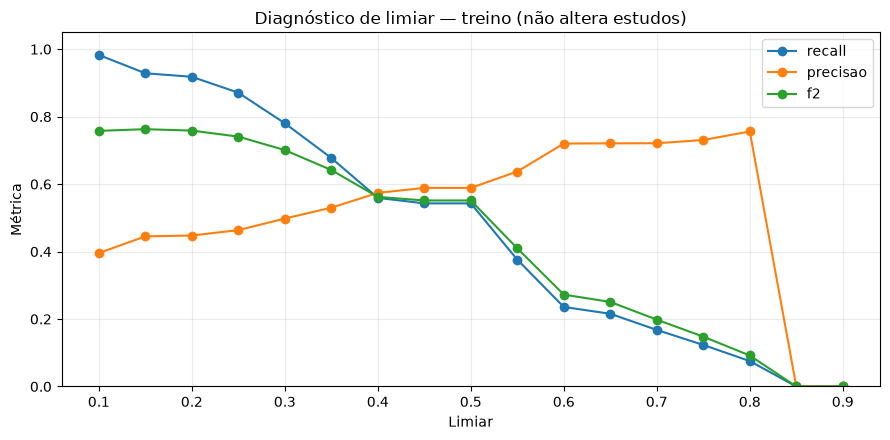

In [22]:
# Diagnóstico de limiar, somente dentro do treinamento.
# Não muda os limiares fixados nas comparações das podas.
from sklearn.model_selection import cross_val_predict
candidato = ESCOLHA_FINAL_RESOLVIDA.get('pre_poda')
if candidato:
    cfg = candidatos_duas_metricas[candidato]
    cv_lim = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=2028)
    probabilidades = cross_val_predict(
        criar_pipeline(cfg['parametros']), X_train, y_train,
        cv=cv_lim, method='predict_proba'
    )[:, 1]
    curvas = []
    for limiar_diag in np.linspace(0.10, 0.90, 17):
        pred = (probabilidades >= limiar_diag).astype(int)
        curvas.append({
            'limiar': limiar_diag,
            'recall': recall_score(y_train, pred, zero_division=0),
            'precisao': precision_score(y_train, pred, zero_division=0),
            'f2': fbeta_score(y_train, pred, beta=2, zero_division=0),
        })
    df_limiares = pd.DataFrame(curvas)
    fig, ax = plt.subplots(figsize=(9, 4.5))
    for nome in ['recall', 'precisao', 'f2']:
        ax.plot(df_limiares['limiar'], df_limiares[nome], marker='o', label=nome)
    ax.set(title='Diagnóstico de limiar — treino (não altera estudos)',
           xlabel='Limiar', ylabel='Métrica', ylim=(0, 1.05))
    ax.legend()
    ax.grid(alpha=.25)
    plt.tight_layout()
    plt.savefig(PASTA_INTERNA / 'curva_limiar_treino.png', dpi=180)
    plt.show()

**13. Avaliação final nos 30% — executar uma vez após congelar modelos**

Esta etapa deve ser executada após a escolha dos parâmetros e do limiar com dados de treinamento. Não ajuste modelos por causa dos resultados abaixo. Como o teste foi consultado no histórico anterior, descreva essa limitação no relatório.

In [23]:
# Avaliação FINAL: somente depois de todos os parâmetros/limiares congelados.
# Auditoria sempre refeita sobre a base em disco, sem estado obsoleto.
if 'confirmar_auditoria_atual' not in globals():
    raise RuntimeError('Execute a seção 2.1: a função de auditoria não foi carregada.')
relatorio_final_auditoria = confirmar_auditoria_atual()
print('Auditoria confirmada para teste final:', relatorio_final_auditoria['metodo'])
if 'configuracoes' not in globals() or not configuracoes:
    raise RuntimeError('Execute a seção 10 para congelar as configurações.')

PASTA_FINAL = PASTA / 'avaliacao_final' / NOME_ESTUDO
PASTA_FINAL.mkdir(parents=True, exist_ok=True)
modelos_treinados, predicoes_teste, historico_final = {}, {}, []

for estrategia, config in configuracoes.items():
    modelo = criar_pipeline(config['parametros'])
    modelo.fit(X_train, y_train)
    limiar = float(config['limiar'])
    treino = metricas_para_limiar(modelo, X_train, y_train, limiar)
    teste = metricas_para_limiar(modelo, X_test, y_test, limiar)
    idx = list(modelo.named_steps['arvore'].classes_).index(1)
    proba = modelo.predict_proba(X_test)[:, idx]
    pred = (proba >= limiar).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    arvore = modelo.named_steps['arvore']
    linha = {
        'experimento': NOME_ESTUDO, 'estrategia': estrategia,
        'modelo': estrategia, 'limiar': limiar,
        'trial': config.get('trial'),
        'profundidade': arvore.get_depth(),
        'folhas': arvore.get_n_leaves(),
        'roc_auc_teste': roc_auc_score(y_test, proba),
        'kappa_teste': cohen_kappa_score(y_test, pred),
        'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp),
    }
    for metrica in treino:
        linha[f'{metrica}_treino'] = treino[metrica]
        linha[f'{metrica}_teste'] = teste[metrica]
    linha['gap_recall'] = treino['recall'] - teste['recall']
    linha['gap_acuracia'] = treino['acuracia'] - teste['acuracia']
    historico_final.append(linha)
    modelos_treinados[estrategia] = modelo
    predicoes_teste[estrategia] = pred
    joblib.dump(modelo, PASTA_FINAL / f'{estrategia}.joblib')

df_final = pd.DataFrame(historico_final)
df_final.to_csv(PASTA_FINAL / 'metricas_finais.csv', index=False)
print('Teste final — 30% reservados; não usar estas métricas para reajustar modelos.')
display(df_final[[
    'estrategia', 'limiar', 'trial', 'recall_teste', 'precisao_teste',
    'f2_teste', 'acuracia_teste', 'gap_recall', 'gap_acuracia',
    'profundidade', 'folhas',
]].round(4))

Auditoria confirmada para teste final: Identidade com a base corrigida previamente auditada
Teste final — 30% reservados; não usar estas métricas para reajustar modelos.


,estrategia,limiar,trial,recall_teste,precisao_teste,f2_teste,acuracia_teste,gap_recall,gap_acuracia,profundidade,folhas
0,baseline,0.24,NaN,0.5501,0.5234,0.5445,0.6631,0.4499,0.3369,22,927
1,pre_poda,0.24,87.0,0.8866,0.4396,0.7367,0.5593,0.0372,0.0330,4,16
2,pos_poda,0.24,36.0,0.8658,0.4526,0.7321,0.5814,0.0394,0.0322,6,15
3,hibrida,0.24,74.0,0.8866,0.4396,0.7367,0.5593,0.0372,0.0330,4,16


**13 — Complemento. Comparação FINAL das quatro estratégias — teste reservado (30%)**

Os quatro modelos congelados na seção 10 são ajustados nos 70% completos na seção 13 e avaliados uma vez nos 30% de teste. Esta é uma fonte diferente de CV1 (seção 6.2) e CV2 (seção 11); não use este resultado para trocar hiperparâmetros, limiares ou candidatos.

,modelo,limiar,recall_teste,f2_teste,precisao_teste,acuracia_teste,profundidade,folhas
0,baseline,0.24,0.5501,0.5445,0.5234,0.6631,22,927
1,pre_poda,0.24,0.8866,0.7367,0.4396,0.5593,4,16
2,pos_poda,0.24,0.8658,0.7321,0.4526,0.5814,6,15
3,hibrida,0.24,0.8866,0.7367,0.4396,0.5593,4,16


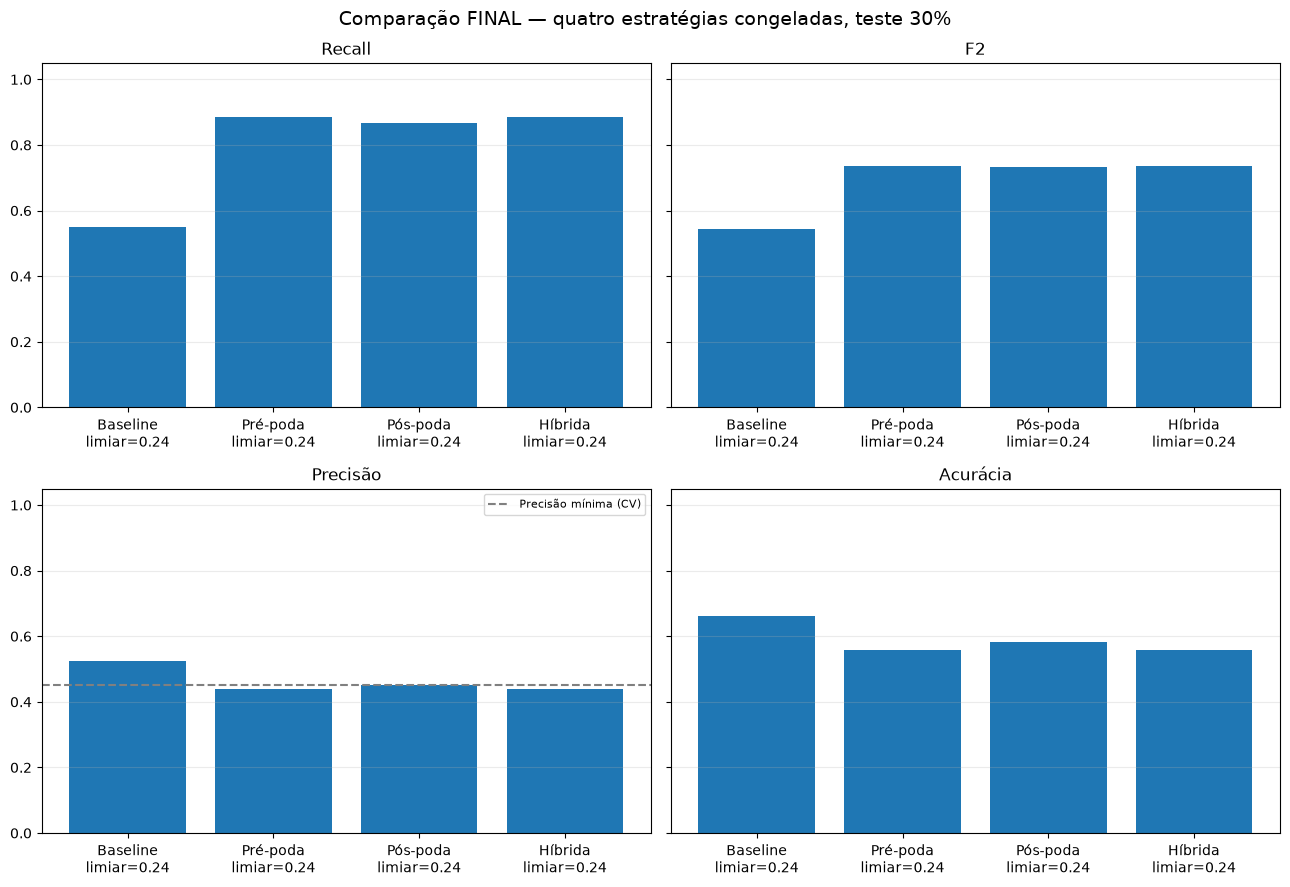

In [24]:
# Visualização das métricas finais (TESTE 30%) dos quatro modelos congelados.
PASTA_FINAL = PASTA / 'avaliacao_final' / NOME_ESTUDO
arquivo_final = PASTA_FINAL / 'metricas_finais.csv'
if not arquivo_final.is_file():
    raise FileNotFoundError('Execute antes a seção 13 para gerar metricas_finais.csv')
df_final = pd.read_csv(arquivo_final)

colunas = ['modelo', 'limiar', 'recall_teste', 'f2_teste',
           'precisao_teste', 'acuracia_teste', 'profundidade', 'folhas']
display(df_final[colunas].round(4))
rotulos_estrategia = {'baseline': 'Baseline', 'pre_poda': 'Pré-poda',
                      'pos_poda': 'Pós-poda', 'hibrida': 'Híbrida'}
nomes = [f'{rotulos_estrategia.get(row.modelo, row.modelo)}\nlimiar={row.limiar:.2f}'
         for row in df_final.itertuples()]
x = np.arange(len(df_final))
fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharey=True)
for ax, (coluna, titulo) in zip(axes.ravel(), [
    ('recall_teste', 'Recall'), ('f2_teste', 'F2'),
    ('precisao_teste', 'Precisão'), ('acuracia_teste', 'Acurácia'),
]):
    ax.bar(x, df_final[coluna])
    ax.set_xticks(x, nomes)
    ax.set_title(titulo)
    ax.set_ylim(0, 1.05)
    ax.grid(axis='y', alpha=.25)
    if coluna == 'precisao_teste' and PRECISAO_MINIMA is not None:
        ax.axhline(PRECISAO_MINIMA, ls='--', color='gray', label='Precisão mínima (CV)')
        ax.legend(fontsize=8)
fig.suptitle('Comparação FINAL — quatro estratégias congeladas, teste 30%', fontsize=14)
plt.tight_layout()
plt.savefig(PASTA_FINAL / 'comparacao_final_quatro_teste.png', dpi=220,
            bbox_inches='tight')
plt.show()

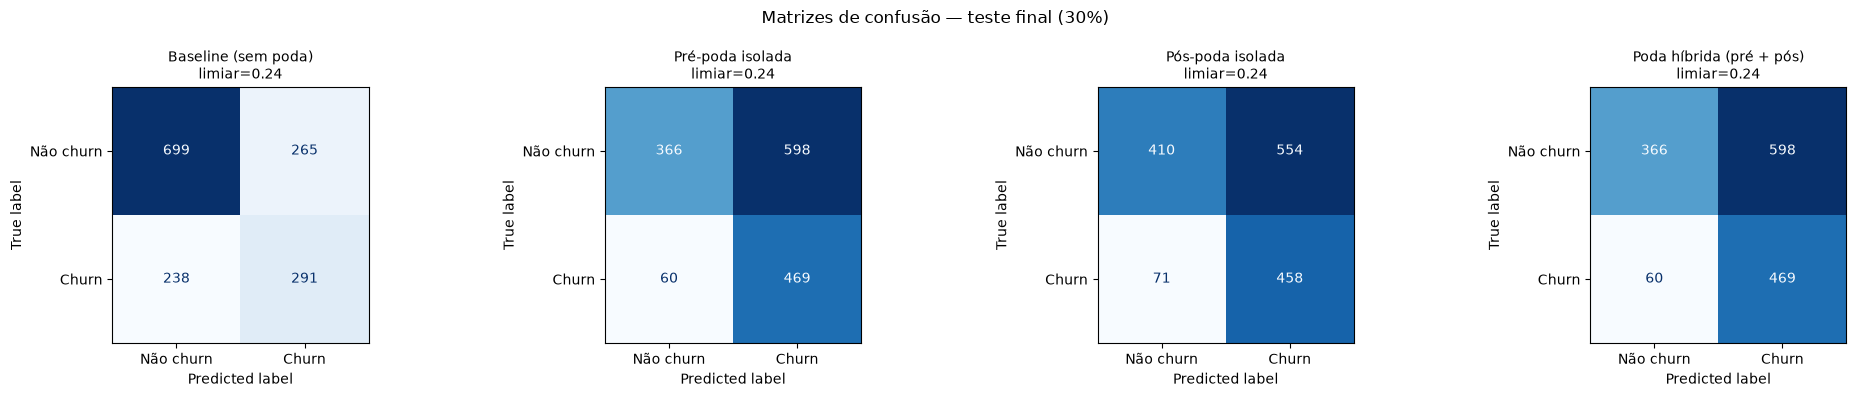

In [25]:
fig, axes = plt.subplots(1, len(predicoes_teste), figsize=(5*len(predicoes_teste), 4))
axes = np.atleast_1d(axes)
for ax, (nome, pred) in zip(axes, predicoes_teste.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, labels=[0, 1],
        display_labels=['Não churn', 'Churn'],
        values_format='d', cmap='Blues', colorbar=False, ax=ax
    )
    ax.set_title(f'{NOMES_ESTRATEGIAS.get(nome, nome)}\nlimiar={configuracoes[nome]["limiar"]:.2f}', fontsize=10)
plt.suptitle('Matrizes de confusão — teste final (30%)')
plt.tight_layout()
plt.savefig(PASTA_FINAL / 'matrizes_confusao.png', dpi=200)
plt.show()

**13.2. Análise de overfitting — gaps entre treino (70%) e teste (30%)**

A seção 13 já treinou os quatro modelos finais nos 70% de treino e calculou as métricas no teste reservado de 30%. Aqui visualizamos as diferenças:
- gap_acuracia = acuracia_treino - acuracia_teste
- gap_recall = recall_treino - recall_teste
  Interpretação: gap positivo e elevado pode indicar dificuldade de generalização; gap pequeno não garante bom modelo (por exemplo, prever tudo como churn pode gerar recall alto em ambos os conjuntos). Esta seção é descritiva e não deve ser usada para reotimizar hiperparâmetros ou limiares, pois consulta o teste final.

,modelo,limiar,recall_treino,recall_teste,gap_recall,acuracia_treino,acuracia_teste,gap_acuracia
0,baseline,0.24,1.0000,0.5501,0.4499,1.0000,0.6631,0.3369
1,pre_poda,0.24,0.9238,0.8866,0.0372,0.5923,0.5593,0.0330
2,pos_poda,0.24,0.9052,0.8658,0.0394,0.6136,0.5814,0.0322
3,hibrida,0.24,0.9238,0.8866,0.0372,0.5923,0.5593,0.0330


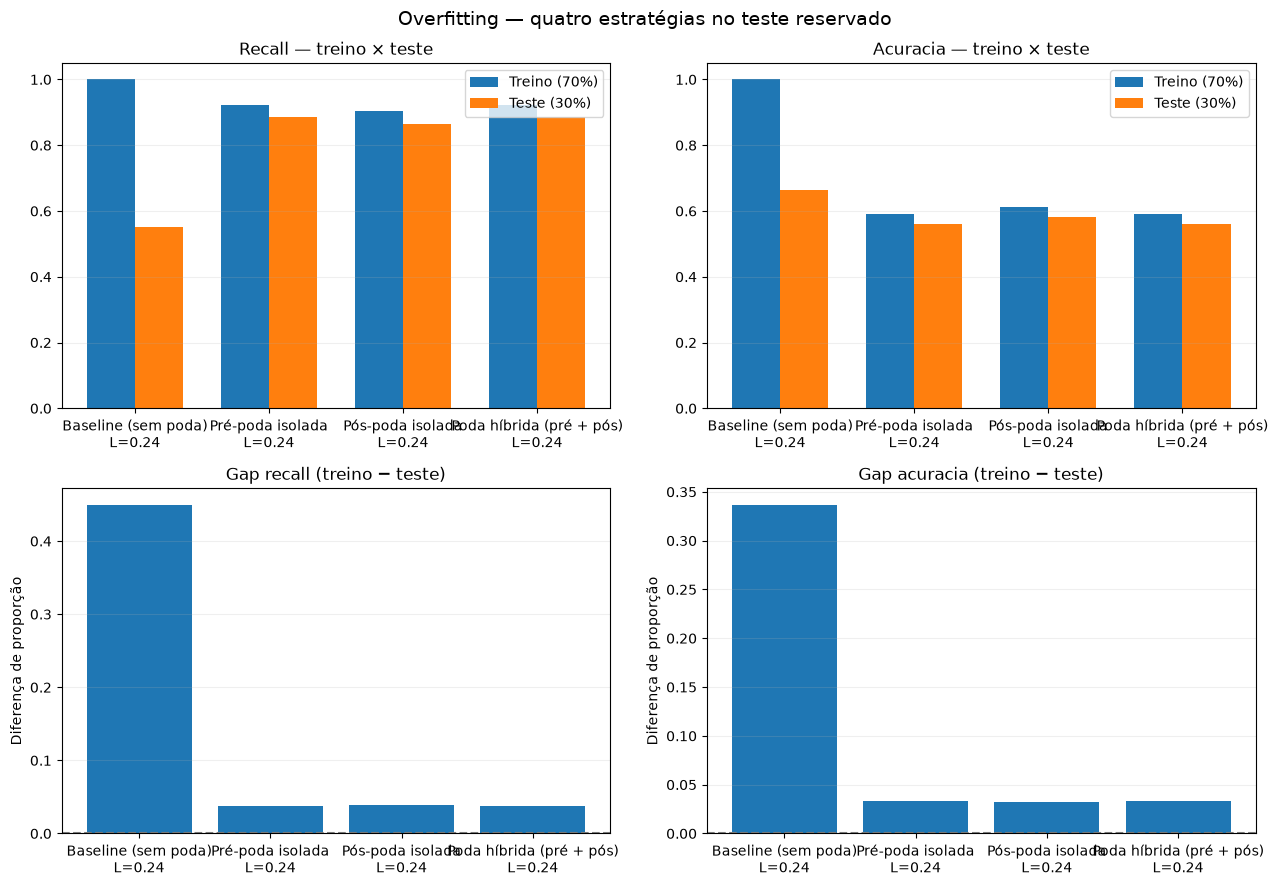

In [26]:
# Treino vs teste — análise de overfitting, sem retreinar.
PASTA_FINAL = PASTA / 'avaliacao_final' / NOME_ESTUDO
arquivo_final = PASTA_FINAL / 'metricas_finais.csv'
if not arquivo_final.is_file():
    raise FileNotFoundError('Execute a seção 13 antes desta análise.')
df_final = pd.read_csv(arquivo_final)
if 'experimento' in df_final and set(df_final['experimento']) != {NOME_ESTUDO}:
    raise ValueError('Métricas finais pertencem a outro experimento.')

for m in ['recall', 'acuracia']:
    df_final[f'gap_{m}'] = df_final[f'{m}_treino'] - df_final[f'{m}_teste']
colunas = ['modelo', 'limiar', 'recall_treino', 'recall_teste', 'gap_recall',
           'acuracia_treino', 'acuracia_teste', 'gap_acuracia']
df_final[colunas].to_csv(PASTA_FINAL / 'overfitting_gaps.csv', index=False)
display(df_final[colunas].round(4))

nomes = [f'{NOMES_ESTRATEGIAS.get(m,m)}\nL={l:.2f}'
         for m,l in zip(df_final['modelo'], df_final['limiar'])]
x = np.arange(len(df_final))
fig, axs = plt.subplots(2, 2, figsize=(13, 9))
for j, metrica in enumerate(['recall', 'acuracia']):
    ax = axs[0, j]
    ax.bar(x-.18, df_final[f'{metrica}_treino'], .36, label='Treino (70%)')
    ax.bar(x+.18, df_final[f'{metrica}_teste'], .36, label='Teste (30%)')
    ax.set_xticks(x, nomes)
    ax.set_ylim(0, 1.05)
    ax.set_title(f'{metrica.capitalize()} — treino × teste')
    ax.grid(axis='y', alpha=.2)
    ax.legend()
    ax = axs[1, j]
    ax.bar(x, df_final[f'gap_{metrica}'])
    ax.axhline(0, ls='--', c='gray')
    ax.set_xticks(x, nomes)
    ax.set_title(f'Gap {metrica} (treino − teste)')
    ax.set_ylabel('Diferença de proporção')
    ax.grid(axis='y', alpha=.2)
fig.suptitle('Overfitting — quatro estratégias no teste reservado', fontsize=14)
plt.tight_layout()
plt.savefig(PASTA_FINAL / 'overfitting_gaps.png', dpi=220, bbox_inches='tight')
plt.show()

for r in df_final.itertuples():
    if r.fn == 0 and r.tn == 0:
        print(f'AVISO: {r.modelo} previu todo o conjunto como churn.')

**13.2.1. Diagnóstico do baseline — acurácia de 100% no treino**

Uma árvore sem regularização pode memorizar o treino e apresentar grande queda no teste.
Para investigar se isso explica a acurácia observada, compare:
- acurácia e recall da árvore no treino e no teste;
- profundidade, nós, folhas e matrizes de confusão da árvore baseline;
- acurácia de um classificador trivial que sempre prevê a classe mais frequente.
Este diagnóstico não altera nem seleciona modelos, tampouco reajusta os parâmetros com base no teste.

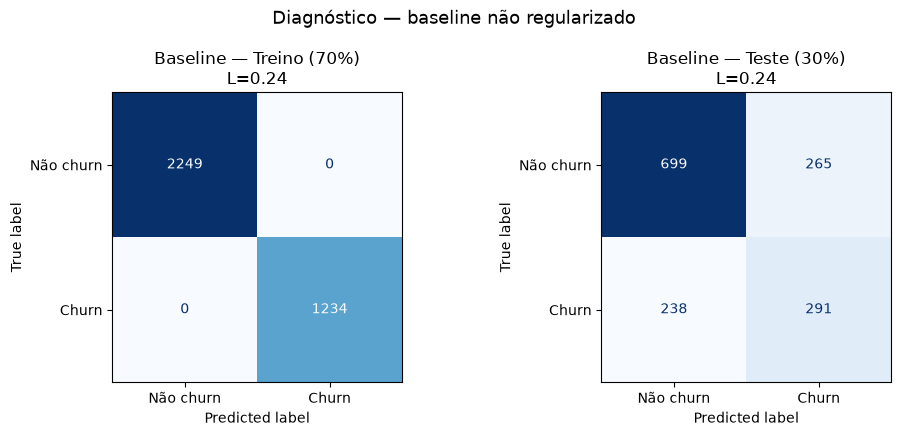

Árvore baseline: profundidade=22, folhas=927, nós=1853


,conjunto,acuracia_baseline,recall_baseline,acuracia_maioria,acuracia_balanceada
0,Treino (70%),1.0000,1.0000,0.6457,1.0000
1,Teste (30%),0.6631,0.5501,0.6457,0.6376


Indício forte de OVERFITTING: gap de acurácia=33.69 p.p.
Acurácia de 100% no treino não implica vazamento por si só.


In [27]:
# Diagnóstico do baseline já treinado (SEM voltar ao Optuna).
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, ConfusionMatrixDisplay

if 'df_final' not in globals() or df_final.empty:
    raise RuntimeError('Execute a seção 13 (avaliação final) antes deste diagnóstico.')
if 'modelos_treinados' not in globals() or 'baseline' not in modelos_treinados:
    raise RuntimeError('O modelo baseline treinado não está na memória. Execute a seção 13.')

modelo_base = modelos_treinados['baseline']
linha_base = df_final.loc[df_final['modelo']=='baseline']
if linha_base.empty:
    raise ValueError('O baseline não está na tabela df_final.')
limiar_base = float(linha_base.iloc[0]['limiar'])
classes_base = list(modelo_base.named_steps['arvore'].classes_)
indice_base = classes_base.index(1)

resultados_base = []
fig,axs=plt.subplots(1,2,figsize=(10,4.4))
for ax,(nome,X_d,y_d) in zip(axs, [('Treino (70%)',X_train,y_train),
                                    ('Teste (30%)',X_test,y_test)]):
    probas = modelo_base.predict_proba(X_d)[:,indice_base]
    previsoes = (probas>=limiar_base).astype(int)
    cm = confusion_matrix(y_d,previsoes,labels=[0,1])
    ConfusionMatrixDisplay(cm,display_labels=['Não churn','Churn']).plot(
        ax=ax,values_format='d',cmap='Blues',colorbar=False)
    ax.set_title(f'Baseline — {nome}\nL={limiar_base:.2f}')
    resultados_base.append({
        'conjunto': nome,
        'acuracia_baseline': accuracy_score(y_d,previsoes),
        'recall_baseline': recall_score(y_d,previsoes,zero_division=0),
        'acuracia_maioria': float((y_d==y_train.mode().iloc[0]).mean()),
        'acuracia_balanceada':balanced_accuracy_score(y_d,previsoes),
    })
fig.suptitle('Diagnóstico — baseline não regularizado',fontsize=13)
fig.tight_layout()
fig.savefig(PASTA_FINAL/'diagnostico_baseline_treino_teste.png',
            dpi=220,bbox_inches='tight')
plt.show()

arv = modelo_base.named_steps['arvore']
print(f'Árvore baseline: profundidade={arv.get_depth()}, '
      f'folhas={arv.get_n_leaves()}, nós={arv.tree_.node_count}')
df_diagnostico = pd.DataFrame(resultados_base)
display(df_diagnostico.round(4))
df_diagnostico.to_csv(PASTA_FINAL/'diagnostico_baseline.csv',index=False)

gap_acc=(df_diagnostico.loc[0,'acuracia_baseline']-
         df_diagnostico.loc[1,'acuracia_baseline'])
if gap_acc>=0.15 and df_diagnostico.loc[0,'acuracia_baseline']>=0.99:
    print(f'Indício forte de OVERFITTING: gap de acurácia={100*gap_acc:.2f} p.p.')
    print('Acurácia de 100% no treino não implica vazamento por si só.')


**13.3. Curvas de aprendizado — tamanho do treino × desempenho (somente 70%)**

Para analisar se o desempenho de treinamento se afasta do desempenho de validação quando mudamos a quantidade de dados, refazemos os quatro modelos com frações crescentes de cada fold de treinamento. Em todos os pontos, avaliamos no fold externo de validação (dentro dos 70% originais), sem utilizar os 30% de teste.
- Usamos as configurações e os limiares já congelados na seção 10, sem nova busca pelo Optuna.
- Para cada fração, a amostra de treino é estratificada; a imputação numérica é ajustada somente nessa amostra. As categorias permanecem nativas.
- O mesmo pré-processamento é reutilizado entre as quatro árvores para reduzir processamento.
- Mostramos acurácia, recall e F2, com médias e desvio-padrão entre folds.
  Leitura: uma distância persistente entre treino alto e validação baixa sugere alta variância/overfitting; curvas baixas e próximas podem sugerir underfitting. Esses gráficos não provam, isoladamente, que a árvore memorizou ruído. Os gráficos das seções 5 (max_depth) e 9 (ccp_alpha) complementam a análise pelo eixo da complexidade.

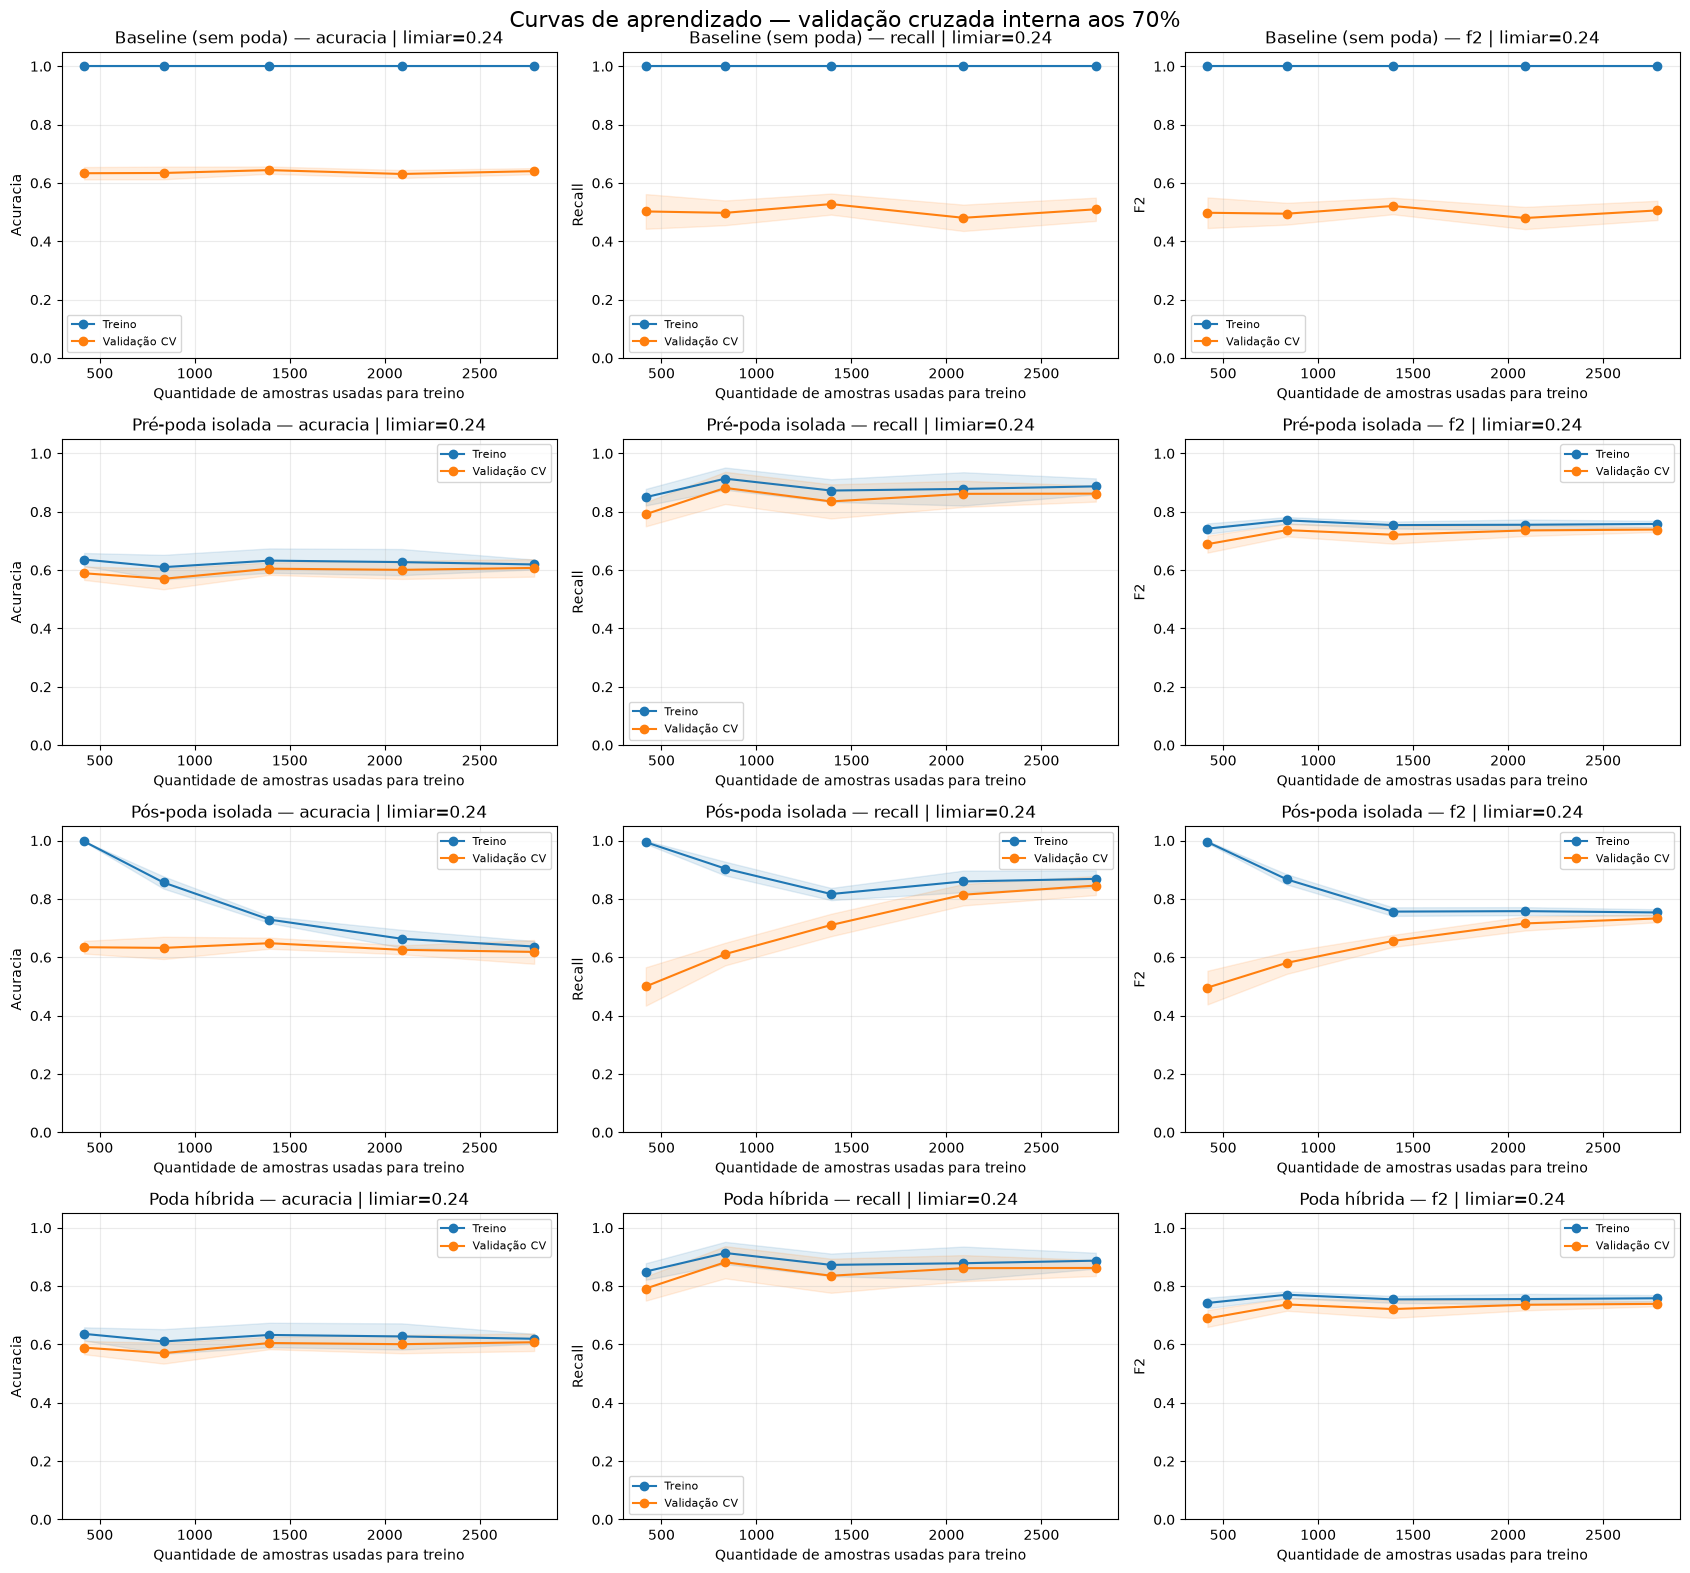

,modelo,limiar,amostras_treino_media,acuracia_treino_media,acuracia_validacao_media,recall_treino_media,recall_validacao_media,f2_treino_media,f2_validacao_media,gap_acuracia_cv,gap_recall_cv,gap_f2_cv
4,baseline,0.24,2786.4,1.0000,0.6405,1.0000,0.5097,1.0000,0.5059,0.3595,0.4903,0.4941
9,hibrida,0.24,2786.4,0.6194,0.6075,0.8872,0.8622,0.7583,0.7391,0.0119,0.0249,0.0192
14,pos_poda,0.24,2786.4,0.6369,0.6184,0.8687,0.8460,0.7536,0.7332,0.0184,0.0227,0.0205
19,pre_poda,0.24,2786.4,0.6194,0.6075,0.8872,0.8622,0.7583,0.7391,0.0119,0.0249,0.0192


As curvas foram calculadas SEM utilizar X_test ou y_test.


In [28]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import accuracy_score, recall_score, fbeta_score

if 'configuracoes' not in globals() or not configuracoes:
    raise RuntimeError('Execute a seção 10 para recuperar/congelar as configurações dos modelos.')

# Parâmetros deste diagnóstico. Não alteram o treinamento final nem o Optuna.
FRACOES_TREINO = [0.15, 0.30, 0.50, 0.75, 1.00]
N_FOLDS_CURVAS = 5
SEMENTE_CURVAS = 2027  # splits diferentes dos usados durante a seleção
CV_CURVAS = StratifiedKFold(n_splits=N_FOLDS_CURVAS, shuffle=True,
                            random_state=SEMENTE_CURVAS)

linhas_curvas = []
for fold, (indices_treino, indices_val) in enumerate(
    CV_CURVAS.split(X_train, y_train), start=1
):
    X_cv_val = X_train.iloc[indices_val]
    y_cv_val = y_train.iloc[indices_val]

    for fracao in FRACOES_TREINO:
        # Subamostra estratificada, retirada APENAS do treino deste fold.
        if fracao == 1.0:
            indices_sub = indices_treino
        else:
            indices_sub, _ = train_test_split(
                indices_treino, train_size=fracao,
                stratify=y_train.iloc[indices_treino],
                random_state=SEMENTE_CURVAS + fold
            )
        X_sub = X_train.iloc[indices_sub]
        y_sub = y_train.iloc[indices_sub]

        # Não usar transformações ajustadas no conjunto completo.
        preproc = criar_preprocessador()
        X_sub_proc = preproc.fit_transform(X_sub)
        X_val_proc = preproc.transform(X_cv_val)

        for nome, config in configuracoes.items():
            params = dict(config['parametros'])
            params.pop('random_state', None)
            params.pop('categorical_features', None)
            arvore = DecisionTreeClassifier(
                categorical_features='from_dtype',
                random_state=42, **params
            )
            arvore.fit(X_sub_proc, y_sub)
            classe_positiva = list(arvore.classes_).index(1)
            limiar = float(config['limiar'])

            def prever(X_proc):
                p = arvore.predict_proba(X_proc)[:, classe_positiva]
                return (p >= limiar).astype(int)

            y_pred_sub = prever(X_sub_proc)
            y_pred_val = prever(X_val_proc)
            metricas = {
                'acuracia_treino': accuracy_score(y_sub, y_pred_sub),
                'acuracia_validacao': accuracy_score(y_cv_val, y_pred_val),
                'recall_treino': recall_score(y_sub, y_pred_sub, zero_division=0),
                'recall_validacao': recall_score(y_cv_val, y_pred_val, zero_division=0),
                'f2_treino': fbeta_score(y_sub, y_pred_sub, beta=2, zero_division=0),
                'f2_validacao': fbeta_score(y_cv_val, y_pred_val, beta=2, zero_division=0),
            }
            linhas_curvas.append({
                'modelo': nome,
                'limiar': limiar,
                'fold': fold,
                'fracao_treino_fold': fracao,
                'amostras_treino': len(X_sub),
                'profundidade': arvore.get_depth(),
                'folhas': arvore.get_n_leaves(),
                **metricas,
            })

df_curvas_folds = pd.DataFrame(linhas_curvas)
df_curvas_folds.to_csv(PASTA_INTERNA / 'curvas_aprendizado_por_fold.csv', index=False)

# Médias e desvio-padrão por modelo e fração de treinamento.
chaves = ['modelo', 'limiar', 'fracao_treino_fold']
metricas_curvas = [
    'acuracia_treino', 'acuracia_validacao',
    'recall_treino', 'recall_validacao',
    'f2_treino', 'f2_validacao',
]
especificacoes = {'amostras_treino_media': ('amostras_treino', 'mean')}
for nome_metrica in metricas_curvas:
    especificacoes[f'{nome_metrica}_media'] = (nome_metrica, 'mean')
    especificacoes[f'{nome_metrica}_dp'] = (nome_metrica, 'std')
df_curvas_resumo = df_curvas_folds.groupby(chaves, as_index=False).agg(
    **especificacoes
)
df_curvas_resumo.to_csv(PASTA_INTERNA / 'curvas_aprendizado_resumo.csv', index=False)

# Três gráficos (acurácia, recall, F2) para cada estratégia.
modelos = list(configuracoes)
fig, axes = plt.subplots(len(modelos), 3, figsize=(17, 4 * len(modelos)),
                         squeeze=False)
for linha, nome in enumerate(modelos):
    dados = df_curvas_resumo.query('modelo == @nome').sort_values('amostras_treino_media')
    x = dados['amostras_treino_media'].to_numpy()
    for coluna, metrica in enumerate(['acuracia', 'recall', 'f2']):
        ax = axes[linha, coluna]
        for fase, rotulo in [('treino', 'Treino'), ('validacao', 'Validação CV')]:
            media = dados[f'{metrica}_{fase}_media'].to_numpy()
            dp = dados[f'{metrica}_{fase}_dp'].fillna(0).to_numpy()
            linha_plot, = ax.plot(x, media, marker='o', label=rotulo)
            ax.fill_between(x, np.clip(media - dp, 0, 1),
                            np.clip(media + dp, 0, 1),
                            color=linha_plot.get_color(), alpha=0.12)
        ax.set_ylim(0, 1.05)
        ax.set_xlabel('Quantidade de amostras usadas para treino')
        ax.set_ylabel(metrica.capitalize())
        nome_legivel = {
            'baseline': 'Baseline (sem poda)',
            'pre_poda': 'Pré-poda isolada',
            'pos_poda': 'Pós-poda isolada',
            'hibrida': 'Poda híbrida',
        }.get(nome, nome)
        ax.set_title(f'{nome_legivel} — {metrica} | limiar={dados["limiar"].iloc[0]:.2f}')
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)
fig.suptitle('Curvas de aprendizado — validação cruzada interna aos 70%', fontsize=16)
plt.tight_layout()
plt.savefig(PASTA_INTERNA / 'curvas_aprendizado_modelos.png', dpi=220,
            bbox_inches='tight')
plt.show()

# Gaps das curvas no maior tamanho de treino: diagnóstico sem consultar teste.
fracao_maxima = max(FRACOES_TREINO)
quadro = df_curvas_resumo.loc[
    df_curvas_resumo['fracao_treino_fold'] == fracao_maxima,
    ['modelo', 'limiar', 'amostras_treino_media'] +
    [f'{m}_{fase}_media' for m in ['acuracia', 'recall', 'f2']
     for fase in ['treino', 'validacao']]
].copy()
for metrica in ['acuracia', 'recall', 'f2']:
    quadro[f'gap_{metrica}_cv'] = (
        quadro[f'{metrica}_treino_media'] -
        quadro[f'{metrica}_validacao_media']
    )
quadro.to_csv(PASTA_INTERNA / 'curvas_aprendizado_gap_cv.csv', index=False)
display(quadro.round(4))
print('As curvas foram calculadas SEM utilizar X_test ou y_test.')


**14. Importância de atributos e interpretação categórica**

In [32]:
for nome, modelo in modelos_treinados.items():
    arvore = modelo.named_steps['arvore']
    atributos = list(modelo.named_steps['preprocessamento'].get_feature_names_out())
    df_imp = pd.DataFrame({
        'atributo': atributos,
        'importancia': arvore.feature_importances_,
    }).sort_values('importancia', ascending=False)
    df_imp.to_csv(PASTA_FINAL / f'importancia_{nome}.csv', index=False)
    print(f'\n{nome} — importância dos atributos')
    display(df_imp.head(12))
    try:
        texto = export_text(arvore, feature_names=atributos, max_depth=4)
        (PASTA_FINAL / f'regras_parciais_{nome}.txt').write_text(texto, encoding='utf-8')
        print(texto)
    except Exception as exc:
        print('Exportação textual indisponível nesta build:', repr(exc))


baseline — importância dos atributos


,atributo,importancia
0,mensalidade_rs,0.297985
6,tempo_cliente_meses,0.259129
2,tipo_contrato,0.078988
3,forma_pagamento,0.070531
7,numero_chamados_total,0.066018
1,atrasos_6m,0.060196
9,numero_chamados_60_dias,0.047636
8,numero_chamados_30_dias,0.042925
10,numero_chamados_90_dias,0.039336
5,debito_automatico,0.028855


|--- tipo_contrato <= -inf
|   |--- numero_chamados_total <= 2.50
|   |   |--- tempo_cliente_meses <= 29.50
|   |   |   |--- atrasos_6m <= 0.80
|   |   |   |   |--- tempo_cliente_meses <= 19.50
|   |   |   |   |   |--- truncated branch of depth 14
|   |   |   |   |--- tempo_cliente_meses >  19.50
|   |   |   |   |   |--- truncated branch of depth 13
|   |   |   |--- atrasos_6m >  0.80
|   |   |   |   |--- fibra_optica <= 0.50
|   |   |   |   |   |--- truncated branch of depth 13
|   |   |   |   |--- fibra_optica >  0.50
|   |   |   |   |   |--- truncated branch of depth 15
|   |   |--- tempo_cliente_meses >  29.50
|   |   |   |--- atrasos_6m <= 2.50
|   |   |   |   |--- tempo_cliente_meses <= 38.50
|   |   |   |   |   |--- truncated branch of depth 12
|   |   |   |   |--- tempo_cliente_meses >  38.50
|   |   |   |   |   |--- truncated branch of depth 6
|   |   |   |--- atrasos_6m >  2.50
|   |   |   |   |--- forma_pagamento <= -inf
|   |   |   |   |   |--- class: 0
|   |   |   |   |---

,atributo,importancia
2,tipo_contrato,0.339585
6,tempo_cliente_meses,0.308003
10,numero_chamados_90_dias,0.146673
7,numero_chamados_total,0.091379
0,mensalidade_rs,0.069316
1,atrasos_6m,0.039385
9,numero_chamados_60_dias,0.005659
5,debito_automatico,0.000000
4,fibra_optica,0.000000
3,forma_pagamento,0.000000


|--- tipo_contrato <= -inf
|   |--- numero_chamados_total <= 2.50
|   |   |--- tempo_cliente_meses <= 29.50
|   |   |   |--- atrasos_6m <= 0.80
|   |   |   |   |--- class: 0
|   |   |   |--- atrasos_6m >  0.80
|   |   |   |   |--- class: 0
|   |   |--- tempo_cliente_meses >  29.50
|   |   |   |--- tempo_cliente_meses <= 38.50
|   |   |   |   |--- class: 0
|   |   |   |--- tempo_cliente_meses >  38.50
|   |   |   |   |--- class: 0
|   |--- numero_chamados_total >  2.50
|   |   |--- tempo_cliente_meses <= 27.50
|   |   |   |--- numero_chamados_90_dias <= 4.50
|   |   |   |   |--- class: 0
|   |   |   |--- numero_chamados_90_dias >  4.50
|   |   |   |   |--- class: 1
|   |   |--- tempo_cliente_meses >  27.50
|   |   |   |--- tempo_cliente_meses <= 40.50
|   |   |   |   |--- class: 0
|   |   |   |--- tempo_cliente_meses >  40.50
|   |   |   |   |--- class: 0
|--- tipo_contrato >  -inf
|   |--- tempo_cliente_meses <= 33.50
|   |   |--- numero_chamados_90_dias <= 2.50
|   |   |   |--- mensal

,atributo,importancia
2,tipo_contrato,0.326199
6,tempo_cliente_meses,0.290969
7,numero_chamados_total,0.214316
0,mensalidade_rs,0.108720
1,atrasos_6m,0.059795
4,fibra_optica,0.000000
3,forma_pagamento,0.000000
5,debito_automatico,0.000000
8,numero_chamados_30_dias,0.000000
9,numero_chamados_60_dias,0.000000


|--- tipo_contrato <= -inf
|   |--- numero_chamados_total <= 2.50
|   |   |--- tempo_cliente_meses <= 29.50
|   |   |   |--- atrasos_6m <= 0.80
|   |   |   |   |--- class: 0
|   |   |   |--- atrasos_6m >  0.80
|   |   |   |   |--- class: 0
|   |   |--- tempo_cliente_meses >  29.50
|   |   |   |--- class: 0
|   |--- numero_chamados_total >  2.50
|   |   |--- tempo_cliente_meses <= 27.50
|   |   |   |--- class: 0
|   |   |--- tempo_cliente_meses >  27.50
|   |   |   |--- class: 0
|--- tipo_contrato >  -inf
|   |--- tempo_cliente_meses <= 33.50
|   |   |--- numero_chamados_total <= 2.50
|   |   |   |--- mensalidade_rs <= 70.05
|   |   |   |   |--- class: 0
|   |   |   |--- mensalidade_rs >  70.05
|   |   |   |   |--- class: 1
|   |   |--- numero_chamados_total >  2.50
|   |   |   |--- mensalidade_rs <= 117.15
|   |   |   |   |--- atrasos_6m <= 1.50
|   |   |   |   |   |--- truncated branch of depth 2
|   |   |   |   |--- atrasos_6m >  1.50
|   |   |   |   |   |--- class: 1
|   |   |   |--

,atributo,importancia
2,tipo_contrato,0.339585
6,tempo_cliente_meses,0.308003
7,numero_chamados_total,0.223111
0,mensalidade_rs,0.069316
1,atrasos_6m,0.039385
10,numero_chamados_90_dias,0.014942
9,numero_chamados_60_dias,0.005659
5,debito_automatico,0.000000
4,fibra_optica,0.000000
3,forma_pagamento,0.000000


|--- tipo_contrato <= -inf
|   |--- numero_chamados_total <= 2.50
|   |   |--- tempo_cliente_meses <= 29.50
|   |   |   |--- atrasos_6m <= 0.80
|   |   |   |   |--- class: 0
|   |   |   |--- atrasos_6m >  0.80
|   |   |   |   |--- class: 0
|   |   |--- tempo_cliente_meses >  29.50
|   |   |   |--- tempo_cliente_meses <= 38.50
|   |   |   |   |--- class: 0
|   |   |   |--- tempo_cliente_meses >  38.50
|   |   |   |   |--- class: 0
|   |--- numero_chamados_total >  2.50
|   |   |--- tempo_cliente_meses <= 27.50
|   |   |   |--- numero_chamados_90_dias <= 4.50
|   |   |   |   |--- class: 0
|   |   |   |--- numero_chamados_90_dias >  4.50
|   |   |   |   |--- class: 1
|   |   |--- tempo_cliente_meses >  27.50
|   |   |   |--- tempo_cliente_meses <= 40.50
|   |   |   |   |--- class: 0
|   |   |   |--- tempo_cliente_meses >  40.50
|   |   |   |   |--- class: 0
|--- tipo_contrato >  -inf
|   |--- tempo_cliente_meses <= 33.50
|   |   |--- numero_chamados_total <= 2.50
|   |   |   |--- mensalid

**14. Importância de atributos e interpretação categórica**

In [34]:
# Identifica as categorias de cada ramo por caminhos REAIS da árvore.
# Evita usar atributos privados sujeitos a mudanças no scikit-learn 1.10.dev.
import re
from sklearn.tree import _tree


def explicar_divisoes_categoricas(modelo, X_referencia, profundidade_maxima=3):
    """Categorias observadas em cada ramo de nós categóricos (somente treino)."""
    arvore = modelo.named_steps['arvore']
    preparador = modelo.named_steps['preprocessamento']
    X_processado = preparador.transform(X_referencia)
    if not isinstance(X_processado, pd.DataFrame):
        raise TypeError('O preprocessador precisa retornar DataFrame com dtype category.')

    atributos = list(X_processado.columns)
    mascara_cat = getattr(arvore, 'is_categorical_', None)
    if mascara_cat is None:
        raise RuntimeError('Esta árvore não expõe is_categorical_; confirme o kernel sklearn 1.10.dev.')
    mascara_cat = np.asarray(mascara_cat, dtype=bool)
    if len(mascara_cat) != len(atributos):
        raise ValueError('Inconsistência entre atributos transformados e árvore.')

    caminhos = arvore.decision_path(X_processado).tocsr()
    estrutura = arvore.tree_
    linhas = []
    cache_amostras = {}

    def amostras_no(no):
        if no not in cache_amostras:
            cache_amostras[no] = caminhos.getcol(no).nonzero()[0]
        return cache_amostras[no]

    def explorar(no, profundidade):
        if profundidade > profundidade_maxima:
            return
        filho_esq = int(estrutura.children_left[no])
        if filho_esq == _tree.TREE_LEAF:
            return
        filho_dir = int(estrutura.children_right[no])
        indice = int(estrutura.feature[no])

        if mascara_cat[indice]:
            coluna = atributos[indice]
            serie = X_processado[coluna]
            if not isinstance(serie.dtype, pd.CategoricalDtype):
                raise RuntimeError(f'{coluna} deveria manter o dtype category.')
            indices_esq = amostras_no(filho_esq)
            indices_dir = amostras_no(filho_dir)
            esq = sorted({str(v) for v in serie.iloc[indices_esq].dropna().unique()})
            dire = sorted({str(v) for v in serie.iloc[indices_dir].dropna().unique()})
            compartilhadas = set(esq) & set(dire)
            if compartilhadas:
                raise RuntimeError(f'Categorias aparecem nos dois ramos de {coluna}, nó {no}: {compartilhadas}')
            ausentes_esq = int(serie.iloc[indices_esq].isna().sum())
            ausentes_dir = int(serie.iloc[indices_dir].isna().sum())
            if not esq and not ausentes_esq:
                raise RuntimeError(f'Não encontrei categorias observadas no ramo esquerdo do nó {no}.')
            condicao = f"{coluna} ∈ {{{', '.join(esq)}}}" if esq else f'{coluna} é ausente'
            if ausentes_esq and esq:
                condicao += ' ou ausente'
            linhas.append({
                'no': no, 'profundidade': profundidade, 'atributo': coluna,
                'ramo_esquerdo_observado': ', '.join(esq) or '(sem categoria não nula)',
                'ramo_direito_observado': ', '.join(dire) or '(sem categoria não nula)',
                'ausentes_esquerda': ausentes_esq,
                'ausentes_direita': ausentes_dir,
                'n_amostras_no': len(amostras_no(no)),
                'rotulo_esquerdo': condicao,
            })
        explorar(filho_esq, profundidade + 1)
        explorar(filho_dir, profundidade + 1)

    explorar(0, 0)
    return pd.DataFrame(linhas, columns=[
        'no', 'profundidade', 'atributo', 'ramo_esquerdo_observado',
        'ramo_direito_observado', 'ausentes_esquerda', 'ausentes_direita',
        'n_amostras_no', 'rotulo_esquerdo'
    ])


def plotar_arvore_com_categorias(modelo, X_referencia, titulo, arquivo, max_depth=3):
    """Substitui o -inf pelo grupo observado à esquerda, sem modificar a árvore."""
    arvore = modelo.named_steps['arvore']
    nomes_atributos = list(modelo.named_steps['preprocessamento'].get_feature_names_out())
    divisoes = explicar_divisoes_categoricas(modelo, X_referencia, max_depth)
    mapa = {int(linha['no']): linha for _, linha in divisoes.iterrows()}

    fig, ax = plt.subplots(figsize=(23, 10))
    anotacoes = plot_tree(
        arvore, feature_names=nomes_atributos,
        class_names=['Não churn', 'Churn'],
        node_ids=True, max_depth=max_depth,
        filled=True, rounded=True, fontsize=8, ax=ax,
    )
    substituidos = set()
    for anotacao in anotacoes:
        linhas = anotacao.get_text().splitlines()
        ids = [re.fullmatch(r'node #(\d+)', item.strip()) for item in linhas]
        ids = [int(m.group(1)) for m in ids if m]
        if not ids:
            continue  # Inclui textos das arestas True/False.
        no = ids[0]
        # Oculta o identificador técnico após usá-lo para associar nós e rótulos.
        linhas = [item for item in linhas if not re.fullmatch(r'node #\d+', item.strip())]
        if no in mapa:
            rotulo = mapa[no]['rotulo_esquerdo']
            for j, item in enumerate(linhas):
                if '<=' in item or '-inf' in item:
                    linhas[j] = rotulo
                    substituidos.add(no)
                    break
        anotacao.set_text('\n'.join(linhas))

    faltantes = set(mapa) - substituidos
    if faltantes:
        plt.close(fig)
        raise RuntimeError(f'Não consegui corrigir os rótulos dos nós categóricos {sorted(faltantes)}. '
                           'A formatação do plot_tree pode ter mudado nesta build.')

    ax.set_title(titulo, fontsize=12, pad=15)
    fig.text(0.5, 0.005,
             'Categorias listadas: observadas no treinamento em cada nó. '
             'Classe exibida: majoritária no nó (pode diferir da previsão com limiar personalizado).',
             ha='center', va='bottom', fontsize=9, color='#555555')
    fig.tight_layout(rect=[0, 0.035, 1, 0.97])
    fig.savefig(arquivo, dpi=230, bbox_inches='tight')
    plt.show()
    return divisoes


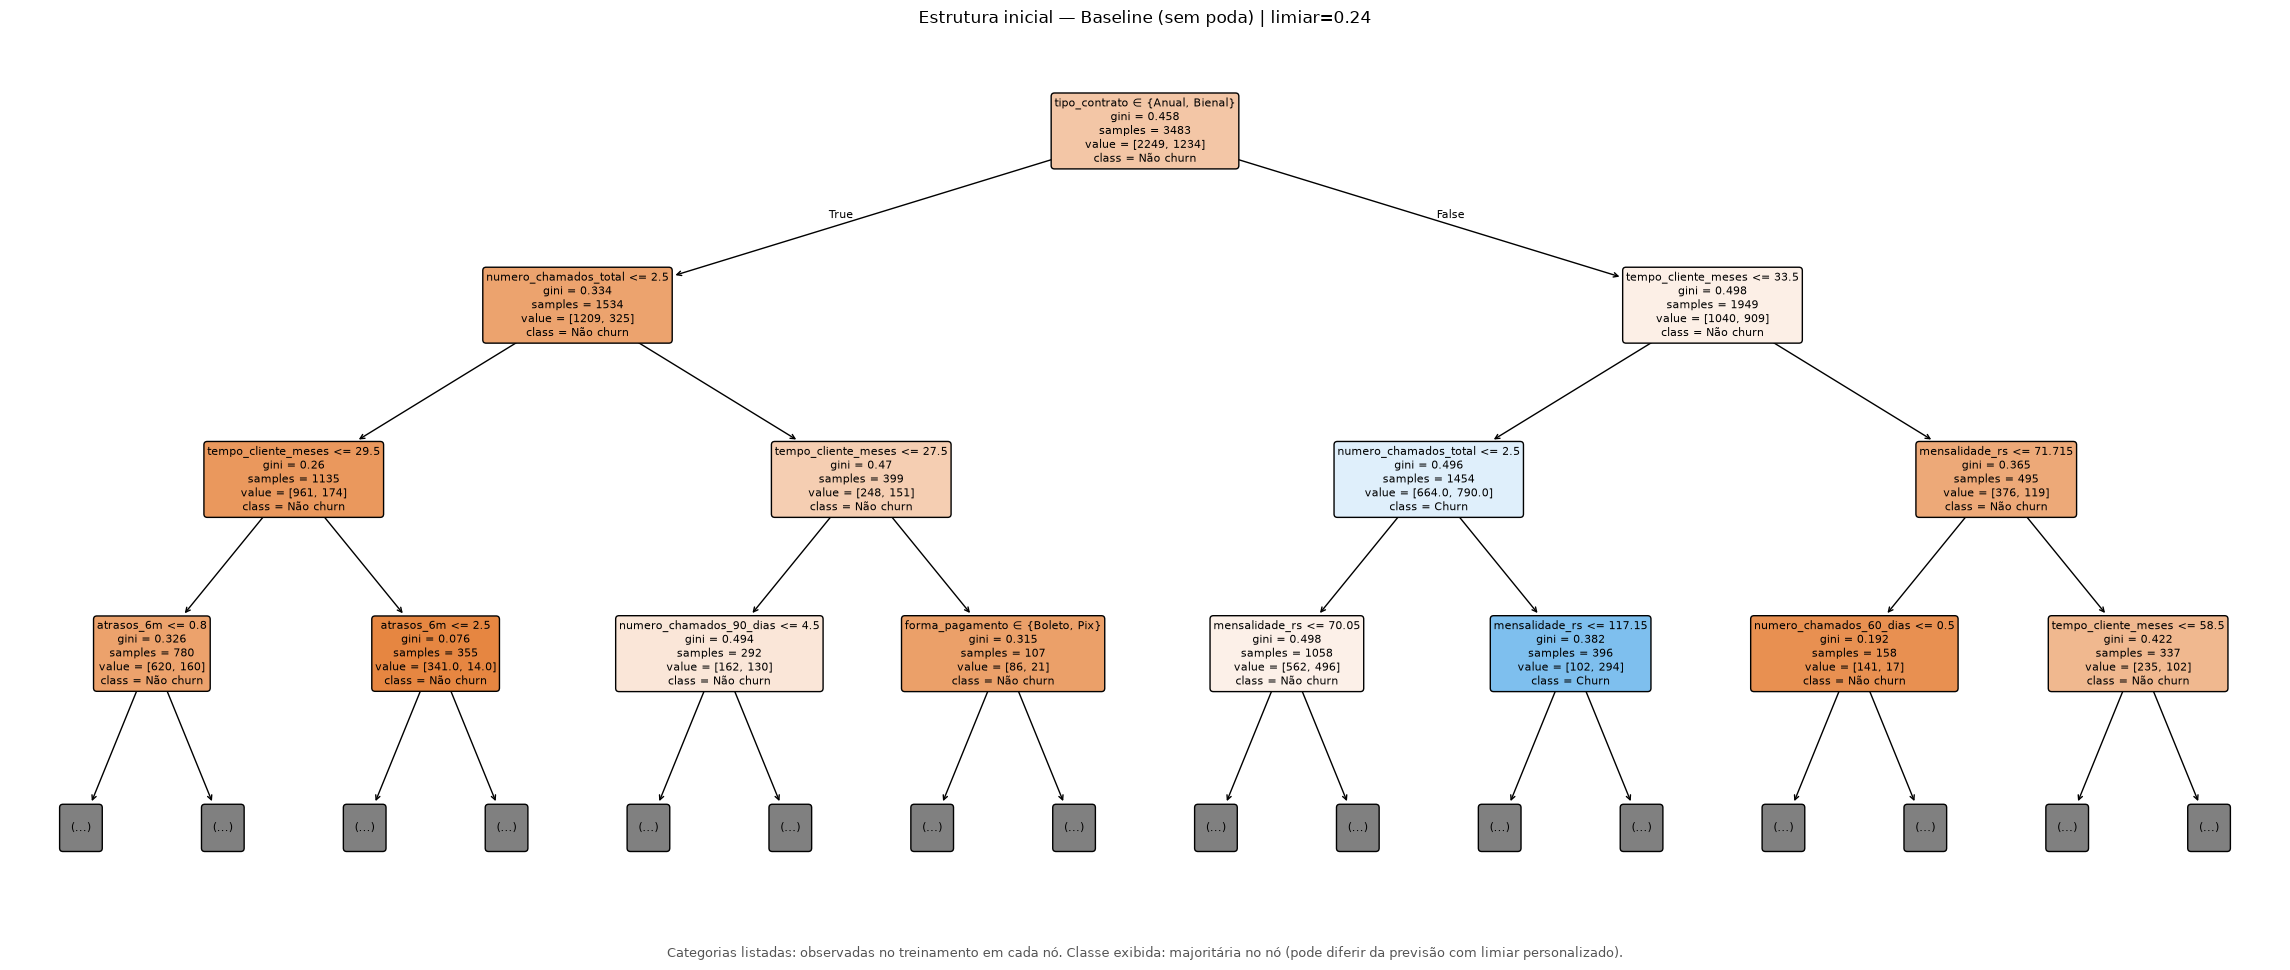


Baseline (sem poda) — divisões categóricas observadas (ramo esquerdo = True):


,no,profundidade,atributo,ramo_esquerdo_observado,ramo_direito_observado,ausentes_esquerda,ausentes_direita,n_amostras_no,rotulo_esquerdo
0,0,0,tipo_contrato,"Anual, Bienal",Mensal,0,17,3483,"tipo_contrato ∈ {Anual, Bienal}"
1,627,3,forma_pagamento,"Boleto, Pix",Cartão,0,0,107,"forma_pagamento ∈ {Boleto, Pix}"


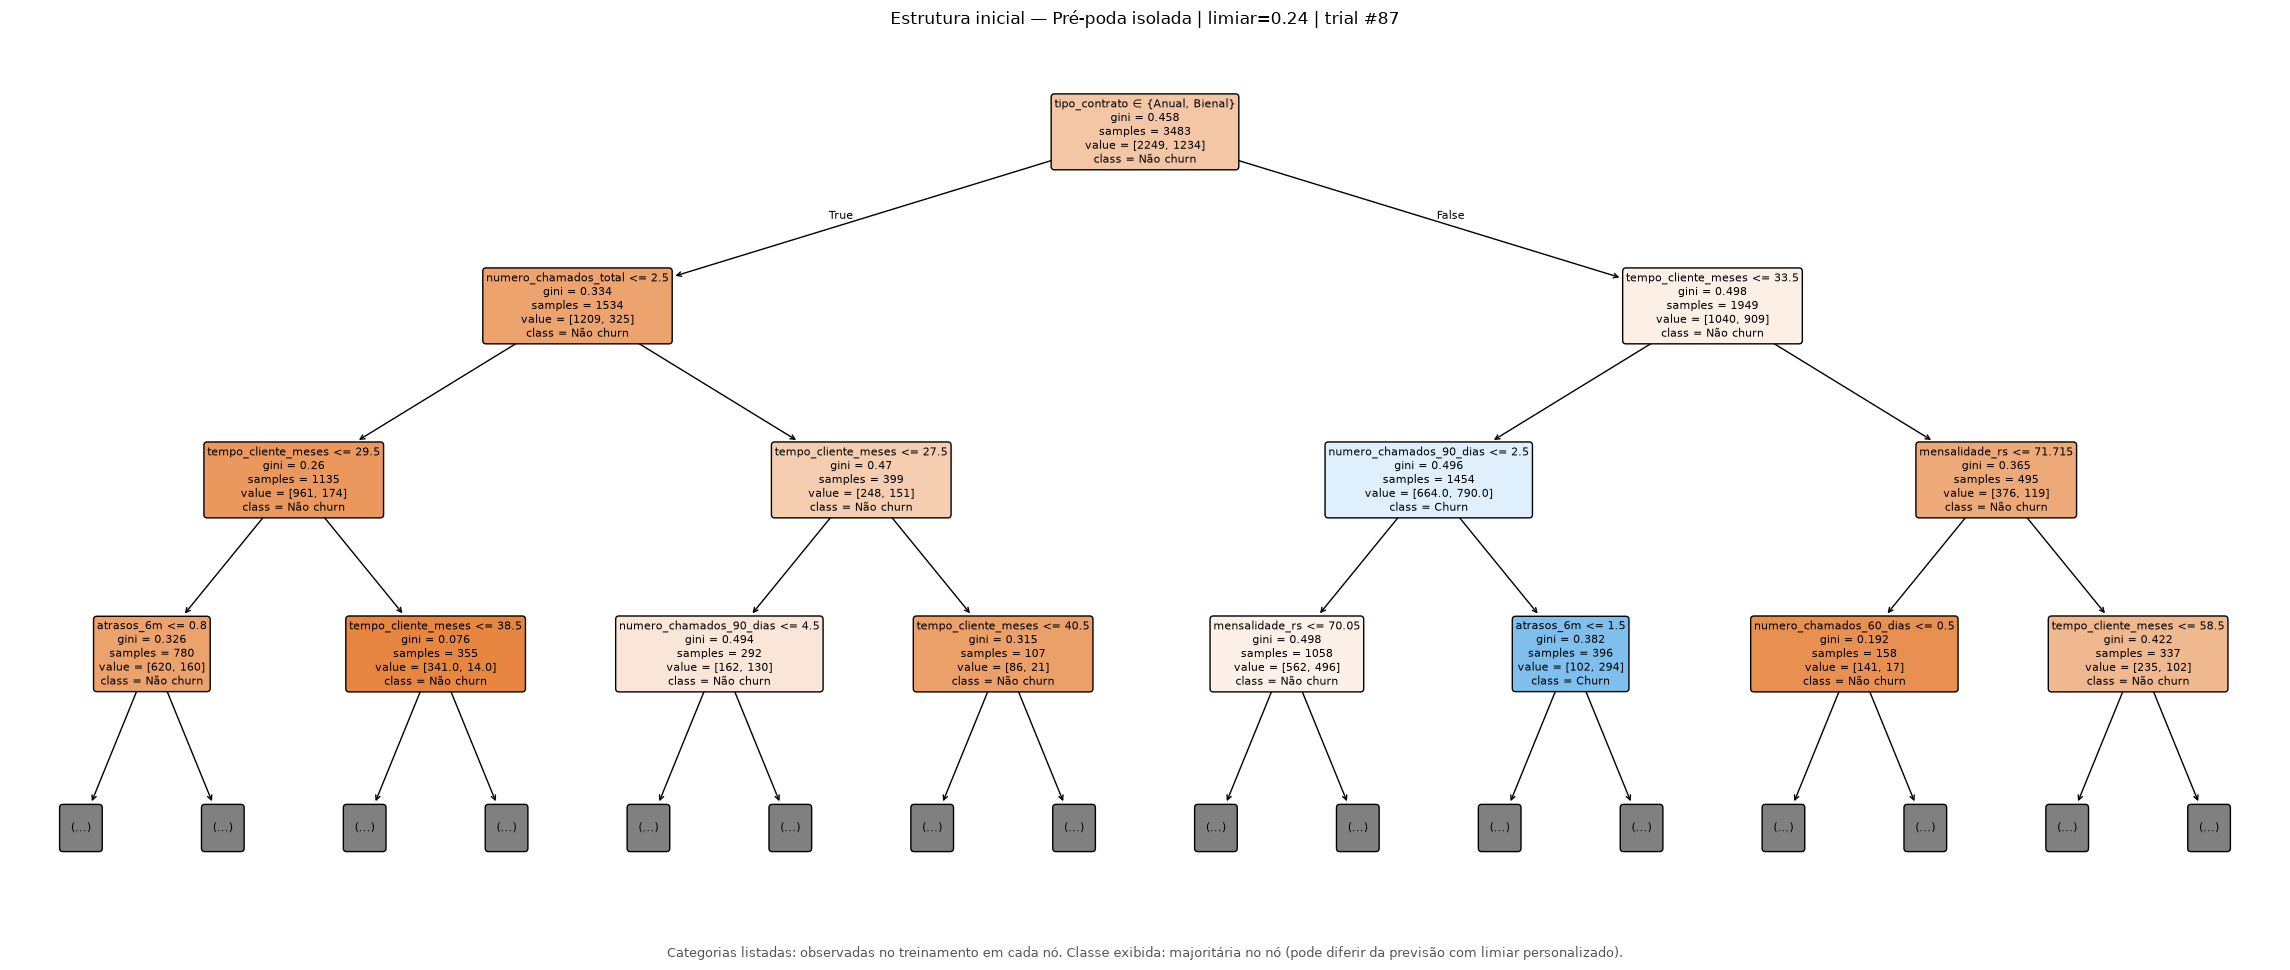


Pré-poda isolada — divisões categóricas observadas (ramo esquerdo = True):


,no,profundidade,atributo,ramo_esquerdo_observado,ramo_direito_observado,ausentes_esquerda,ausentes_direita,n_amostras_no,rotulo_esquerdo
0,0,0,tipo_contrato,"Anual, Bienal",Mensal,0,17,3483,"tipo_contrato ∈ {Anual, Bienal}"


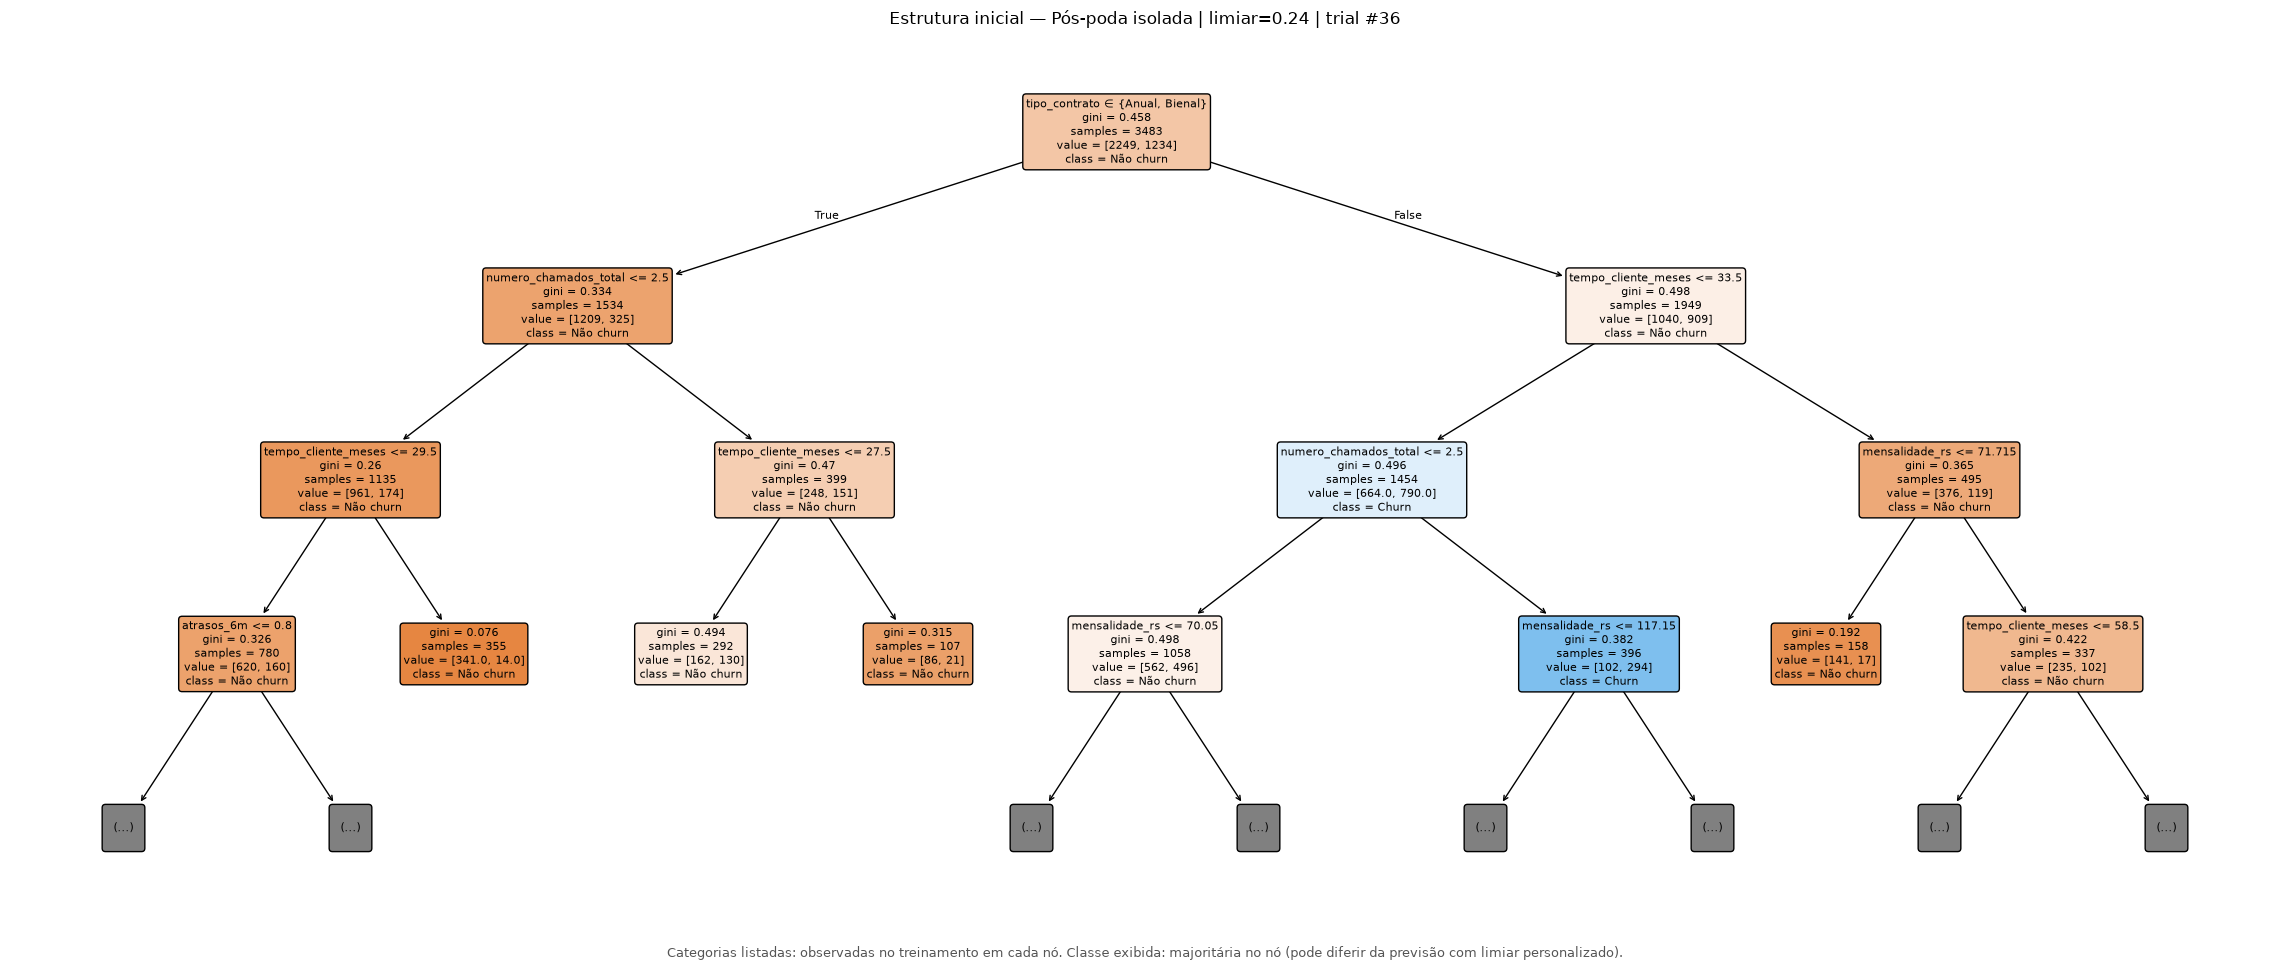


Pós-poda isolada — divisões categóricas observadas (ramo esquerdo = True):


,no,profundidade,atributo,ramo_esquerdo_observado,ramo_direito_observado,ausentes_esquerda,ausentes_direita,n_amostras_no,rotulo_esquerdo
0,0,0,tipo_contrato,"Anual, Bienal",Mensal,0,17,3483,"tipo_contrato ∈ {Anual, Bienal}"


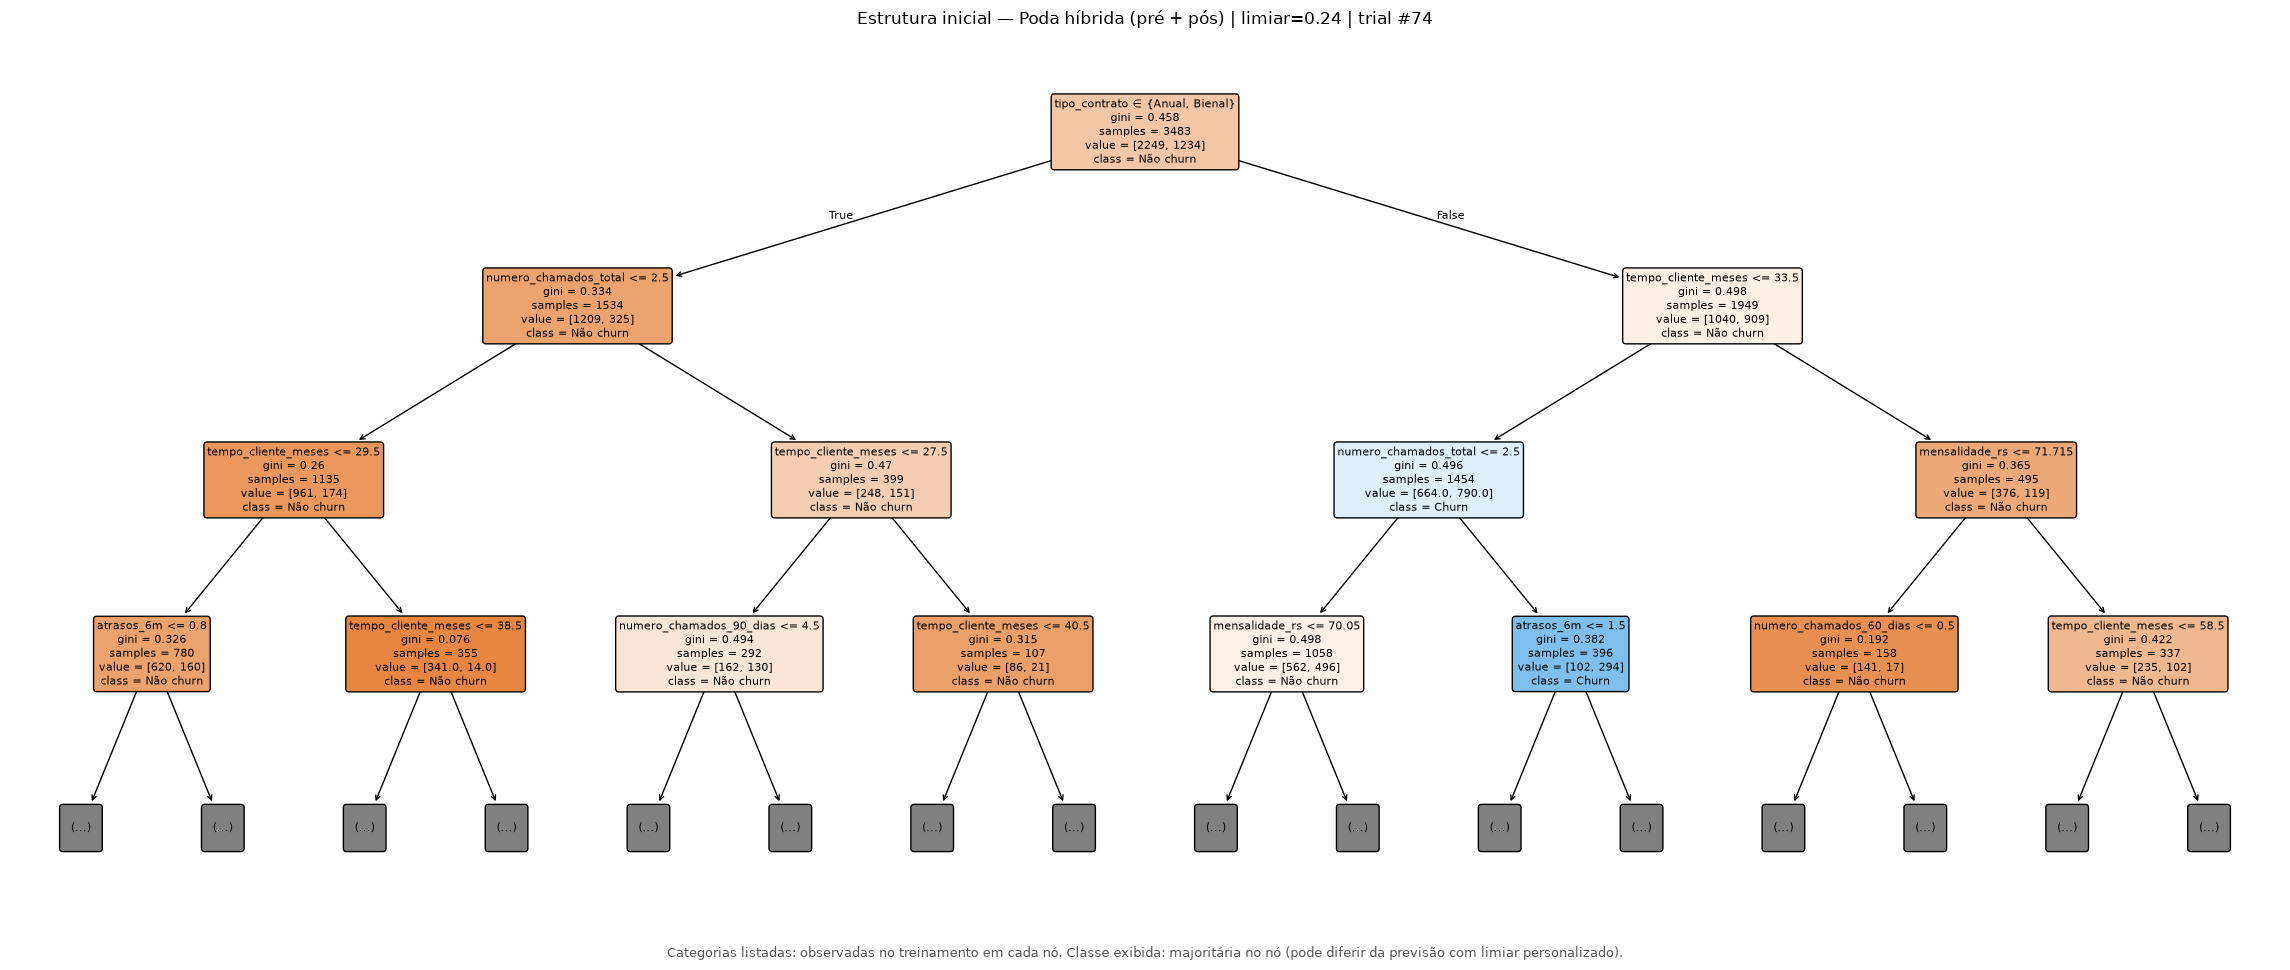


Poda híbrida (pré + pós) — divisões categóricas observadas (ramo esquerdo = True):


,no,profundidade,atributo,ramo_esquerdo_observado,ramo_direito_observado,ausentes_esquerda,ausentes_direita,n_amostras_no,rotulo_esquerdo
0,0,0,tipo_contrato,"Anual, Bienal",Mensal,0,17,3483,"tipo_contrato ∈ {Anual, Bienal}"


In [35]:
# Um único gráfico por modelo; usa os modelos JÁ treinados na seção 13.
# O cálculo só consulta X_train (70%) e não consulta os rótulos nem X_test.
if 'modelos_treinados' not in globals() or not modelos_treinados:
    raise RuntimeError('Execute a seção 13 para criar modelos_treinados (ou carregue os .joblib).')

for nome, modelo in modelos_treinados.items():
    descricao = {
        'baseline': 'Baseline (sem poda)',
        'pre_poda': 'Pré-poda isolada',
        'pos_poda': 'Pós-poda isolada',
        'hibrida': 'Poda híbrida (pré + pós)',
    }.get(nome, nome)
    config = configuracoes.get(nome, {}) if 'configuracoes' in globals() else {}
    limiar_texto = f" | limiar={float(config['limiar']):.2f}" if 'limiar' in config else ''
    trial_texto = f" | trial #{config['trial']}" if config.get('trial') is not None else ''
    titulo = f'Estrutura inicial — {descricao}{limiar_texto}{trial_texto}'

    df_cortes = plotar_arvore_com_categorias(
        modelo, X_train, titulo,
        PASTA_FINAL / f'arvore_{nome}_categorias_legiveis.png', max_depth=3
    )
    df_cortes.to_csv(PASTA_FINAL / f'divisoes_categoricas_{nome}.csv', index=False)
    print(f'\n{descricao} — divisões categóricas observadas (ramo esquerdo = True):')
    display(df_cortes)
